# EDA – Conectividad fija en Argentina (2014–2024)
**Integrante 2: análisis exploratorio, estadísticas, gráficos e hipótesis**

Este notebook cubre estructura, calidad inicial, estadística descriptiva, distribuciones, variables categóricas y numéricas, cruces, correlaciones, evolución temporal, patrones, outliers y conclusiones exploratorias.

> **Importante:** el análisis parte de las tablas `fact_*` y dimensiones del modelo SQLite. El notebook inspecciona el esquema y propone columnas automáticamente, pero hay una sección de configuración para corregir los nombres si el reconocimiento no coincide con tu base. No modifica la base ni elimina outliers.


## 1. Configuración

In [2]:
from pathlib import Path
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
warnings.filterwarnings("ignore", category=FutureWarning)

DB_PATH = Path("../database/conectividad.db")

if not DB_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró la base en: {DB_PATH.resolve()}\n"
        "Modificá DB_PATH para apuntar a tu archivo .db o .sqlite."
    )

conn = sqlite3.connect(DB_PATH)
print("Base conectada:", DB_PATH.resolve())


Base conectada: C:\Users\Admin\Downloads\conectividad-fija-argentina\conectividad-fija-argentina\database\conectividad.db


## 2. Revisión de estructura del dataset y esquema disponible

In [3]:
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name",
    conn
)
views = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='view' ORDER BY name",
    conn
)
display(tables)
display(views)

def table_columns(table_name):
    return pd.read_sql_query(f'PRAGMA table_info("{table_name}")', conn)

schema_rows = []
for table_name in tables["name"]:
    info = table_columns(table_name)
    for _, row in info.iterrows():
        schema_rows.append({
            "tabla": table_name,
            "columna": row["name"],
            "tipo": row["type"],
            "not_null": bool(row["notnull"]),
            "primary_key": bool(row["pk"])
        })
schema = pd.DataFrame(schema_rows)
display(schema)


,name
0,dim_categoria_velocidad
1,dim_localidad
2,dim_periodo
3,dim_provincia
4,dim_provincia_alias
5,dim_tecnologia
6,dim_tecnologia_alias
7,fact_accesos_categoria_localidad
8,fact_accesos_categoria_provincia
9,fact_accesos_provincia


,name
0,quality_category_period_mismatches
1,quality_category_total_mismatches
2,quality_fact_out_of_scope_rows
3,quality_issues
4,quality_linkindec_collisions
5,quality_linkindec_cross_source_mismatches
6,quality_locality_source_coverage
7,quality_missing_provincia_periodo
8,quality_numeric_anomalies
9,quality_out_of_scope_source_rows


,tabla,columna,tipo,not_null,primary_key
0,dim_categoria_velocidad,categoria_velocidad_id,INTEGER,False,True
1,dim_categoria_velocidad,etiqueta_original,TEXT,True,False
2,dim_localidad,localidad_id,INTEGER,False,True
3,dim_localidad,provincia_id,INTEGER,True,False
4,dim_localidad,departamento_key,TEXT,True,False
...,...,...,...,...,...
122,stg_velocidad_provincia,provincia_key,TEXT,False,False
123,stg_velocidad_provincia,anio_valor,INTEGER,False,False
124,stg_velocidad_provincia,trimestre_valor,INTEGER,False,False
125,stg_velocidad_provincia,mbps_raw,TEXT,True,False


### Interpretación de la estructura de datos

La exploración inicial de la base de datos SQLite permitió identificar **20 tablas y 16 vistas de control de calidad**, evidenciando una organización de los datos orientada al análisis de la conectividad fija en Argentina.

Las tablas se encuentran distribuidas en tres grupos principales: tablas de staging (`stg_*`), utilizadas durante la preparación de los datos; tablas de dimensiones (`dim_*`), que permiten identificar provincias, períodos, tecnologías y localidades; y tablas de hechos (`fact_*`), que almacenan los indicadores cuantitativos necesarios para el análisis exploratorio.

Asimismo, se identificaron vistas de calidad (`quality_*`) destinadas a facilitar la detección de posibles inconsistencias, diferencias entre fuentes y problemas de integridad de los datos.

La revisión del esquema mediante `PRAGMA table_info` permitió reconocer los nombres de las columnas, sus tipos de datos y las restricciones declaradas, facilitando la selección de variables y la comprensión de las relaciones entre las tablas.

Esta estructura constituye la base para analizar la evolución temporal de los accesos, la transformación tecnológica y las desigualdades territoriales en la conectividad fija argentina durante el período 2014–2024.

### 2.1 Volumen de registros por tabla

,tabla,filas
15,stg_accesos_categoria_provincia,26614
7,fact_accesos_categoria_localidad,24990
14,stg_accesos_categoria_localidad,24990
8,fact_accesos_categoria_provincia,20737
11,fact_accesos_tecnologia_localidad,12100
16,stg_accesos_tecnologia_localidad,12100
10,fact_accesos_tecnologia,5280
1,dim_localidad,4694
18,stg_penetracion_provincia,1200
19,stg_velocidad_provincia,1200


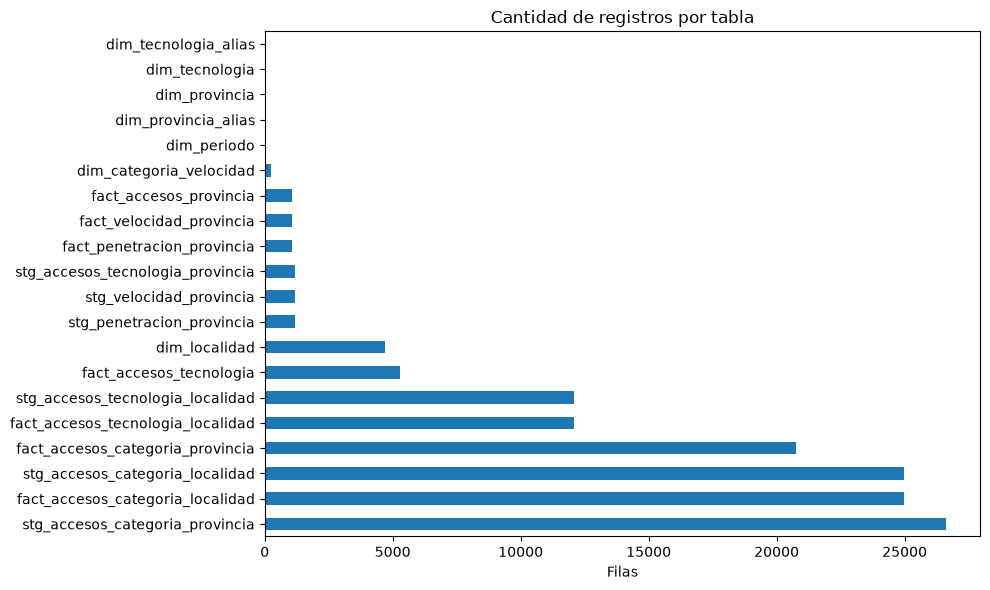

In [4]:
row_counts = []
for table_name in tables["name"]:
    n = pd.read_sql_query(f'SELECT COUNT(*) AS n FROM "{table_name}"', conn).iloc[0, 0]
    row_counts.append({"tabla": table_name, "filas": int(n)})
row_counts = pd.DataFrame(row_counts).sort_values("filas", ascending=False)
display(row_counts)
row_counts.plot(kind="barh", x="tabla", y="filas", legend=False, figsize=(10, max(4, len(row_counts)*0.3)))
plt.title("Cantidad de registros por tabla")
plt.xlabel("Filas")
plt.ylabel("")
plt.tight_layout()
plt.show()


### Interpretación del volumen de registros

El análisis del volumen de registros permite identificar diferencias en la granularidad y cobertura de las tablas que componen la base de datos.

Se observa que `dim_periodo` contiene 44 registros, correspondientes a los trimestres comprendidos entre 2014 y 2024, mientras que `dim_provincia` incluye las 24 jurisdicciones argentinas.

Las tablas `fact_accesos_provincia`, `fact_velocidad_provincia` y `fact_penetracion_provincia` presentan 1.056 registros cada una, cantidad consistente con una observación por provincia y trimestre durante el período estudiado.

Por su parte, `fact_accesos_tecnologia` contiene 5.280 registros, debido a que cada combinación de provincia y período se desagrega en cinco tecnologías de conexión: ADSL, Cablemodem, Fibra Optica, Wireless y Otros.

Las tablas de categorías de velocidad y localidades presentan mayores volúmenes debido a su mayor nivel de desagregación. Asimismo, se observan diferencias entre algunas tablas de staging y sus correspondientes tablas de hechos, relacionadas potencialmente con los criterios de selección, transformación y vinculación aplicados durante el ETL.

Estos resultados permiten comprender la estructura y granularidad de los datos disponibles, aspectos fundamentales para realizar agregaciones y comparaciones correctas durante el análisis exploratorio.

## 3. Carga de tablas de hechos

Se cargan las tablas de hechos principales. Si una tabla no existe, se informa y el resto del notebook puede continuar cuando no dependa de ella.

In [5]:
FACT_TABLES = [
    "fact_accesos_provincia",
    "fact_accesos_tecnologia",
    "fact_velocidad_provincia",
    "fact_penetracion_provincia",
    "fact_accesos_categoria_provincia",
    "fact_accesos_tecnologia_localidad",
    "fact_accesos_categoria_localidad",
]

data = {}
for t in FACT_TABLES:
    if t in set(tables["name"]):
        data[t] = pd.read_sql_query(f'SELECT * FROM "{t}"', conn)
        print(f"{t}: {len(data[t]):,} filas | {len(data[t].columns)} columnas")
    else:
        print(f"AVISO: no existe {t}")

for t, df in data.items():
    print("\n", t, "->", list(df.columns))


fact_accesos_provincia: 1,056 filas | 5 columnas
fact_accesos_tecnologia: 5,280 filas | 6 columnas
fact_velocidad_provincia: 1,056 filas | 5 columnas
fact_penetracion_provincia: 1,056 filas | 6 columnas
fact_accesos_categoria_provincia: 20,737 filas | 6 columnas
fact_accesos_tecnologia_localidad: 12,100 filas | 4 columnas
fact_accesos_categoria_localidad: 24,990 filas | 4 columnas

 fact_accesos_provincia -> ['anio', 'trimestre', 'provincia_id', 'accesos_total', 'source_row']

 fact_accesos_tecnologia -> ['anio', 'trimestre', 'provincia_id', 'tecnologia_id', 'accesos', 'source_row']

 fact_velocidad_provincia -> ['anio', 'trimestre', 'provincia_id', 'mbps_media', 'source_row']

 fact_penetracion_provincia -> ['anio', 'trimestre', 'provincia_id', 'accesos_100_hogares', 'accesos_100_habitantes', 'source_row']

 fact_accesos_categoria_provincia -> ['anio', 'trimestre', 'provincia_id', 'categoria_velocidad_id', 'accesos', 'source_row']

 fact_accesos_tecnologia_localidad -> ['localidad_id'

## 4. Perfil de calidad inicial: nulos, duplicados y tipos

Los duplicados se revisan sobre filas completas. La clave lógica puede ser diferente según cada tabla, por lo que esta revisión no reemplaza las vistas `quality_*` del SQL.

In [7]:
quality_profile = []
for t, df in data.items():
    quality_profile.append({
        "tabla": t,
        "filas": len(df),
        "columnas": len(df.columns),
        "celdas_nulas": int(df.isna().sum().sum()),
        "porcentaje_celdas_nulas": round(df.isna().sum().sum() / max(df.size, 1) * 100, 2),
        "filas_duplicadas_completas": int(df.duplicated().sum())
    })
display(pd.DataFrame(quality_profile))


for t, df in data.items():
    nulos = (df.isna().mean() * 100).round(2)
    nulos = nulos[nulos > 0].sort_values(ascending=False)

    print(f"\n{t} - porcentaje de nulos por columna")

    if nulos.empty:
        print("No se detectaron valores nulos.")
    else:
        display(nulos.to_frame(name="porcentaje_nulos"))



,tabla,filas,columnas,celdas_nulas,porcentaje_celdas_nulas,filas_duplicadas_completas
0,fact_accesos_provincia,1056,5,0,0.000,0
1,fact_accesos_tecnologia,5280,6,0,0.000,0
2,fact_velocidad_provincia,1056,5,0,0.000,0
3,fact_penetracion_provincia,1056,6,0,0.000,0
4,fact_accesos_categoria_provincia,20737,6,0,0.000,0
5,fact_accesos_tecnologia_localidad,12100,4,0,0.000,0
6,fact_accesos_categoria_localidad,24990,4,0,0.000,0



fact_accesos_provincia - porcentaje de nulos por columna
No se detectaron valores nulos.

fact_accesos_tecnologia - porcentaje de nulos por columna
No se detectaron valores nulos.

fact_velocidad_provincia - porcentaje de nulos por columna
No se detectaron valores nulos.

fact_penetracion_provincia - porcentaje de nulos por columna
No se detectaron valores nulos.

fact_accesos_categoria_provincia - porcentaje de nulos por columna
No se detectaron valores nulos.

fact_accesos_tecnologia_localidad - porcentaje de nulos por columna
No se detectaron valores nulos.

fact_accesos_categoria_localidad - porcentaje de nulos por columna
No se detectaron valores nulos.


### Interpretación del perfil de calidad inicial

El análisis inicial de calidad de datos se realizó sobre las siete tablas de hechos utilizadas en el EDA, con el objetivo de identificar valores nulos y registros completamente duplicados.

Los resultados muestran que las tablas analizadas no presentan valores nulos ni filas duplicadas completas. Esto indica que, para las variables y registros disponibles en estas tablas, no se identificaron problemas de completitud ni duplicaciones exactas mediante los controles aplicados.

Sin embargo, estos resultados corresponden a las tablas analíticas generadas después del proceso de extracción, transformación y carga (ETL), por lo que no permiten afirmar que los archivos originales de ENACOM estuvieran libres de inconsistencias.

Además, la detección de duplicados completos no reemplaza la validación de claves naturales o combinaciones de campos que deberían identificar registros únicos. Para ello, el proyecto dispone de controles SQL específicos mediante las vistas `quality_*`, que permiten examinar duplicados, valores numéricos inválidos, problemas de cobertura y diferencias entre fuentes.

En consecuencia, esta revisión constituye un primer diagnóstico de calidad de los datos utilizados en Python, complementario a los controles de calidad implementados en SQL.

## 5. Identificación y mapeo de variables para el análisis

### Objetivo del mapeo de variables

En esta sección se identifican y configuran las columnas de las tablas de hechos que serán utilizadas durante el análisis exploratorio.

Mediante la función `choose_col()` y el diccionario `MAP`, se establecen correspondencias entre las variables analíticas y los nombres de las columnas disponibles en los DataFrames.

Este procedimiento permite verificar la disponibilidad de los campos necesarios para analizar accesos, tecnologías, velocidades, penetración y distribución territorial, facilitando su utilización en las siguientes etapas del EDA.

Las categorías de velocidad se conservan según sus etiquetas originales, sin asumir rangos numéricos o unidades que no estén documentados en las fuentes.

Los resultados impresos permiten comprobar que las variables fueron identificadas correctamente.

In [8]:
def choose_col(df, candidates):
    lower_map = {str(c).lower(): c for c in df.columns}

    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    return None


MAP = {
    "fact_accesos_provincia": {
        "anio": ["anio"],
        "trimestre": ["trimestre"],
        "provincia": ["provincia_id"],
        "accesos": ["accesos_total"]
    },

    "fact_accesos_tecnologia": {
        "anio": ["anio"],
        "trimestre": ["trimestre"],
        "provincia": ["provincia_id"],
        "tecnologia": ["tecnologia_id"],
        "accesos": ["accesos"]
    },

    "fact_velocidad_provincia": {
        "anio": ["anio"],
        "trimestre": ["trimestre"],
        "provincia": ["provincia_id"],
        "velocidad": ["mbps_media"]
    },

    "fact_penetracion_provincia": {
        "anio": ["anio"],
        "trimestre": ["trimestre"],
        "provincia": ["provincia_id"],
        "hogares": ["accesos_100_hogares"],
        "habitantes": ["accesos_100_habitantes"]
    },

    "fact_accesos_categoria_provincia": {
        "anio": ["anio"],
        "trimestre": ["trimestre"],
        "provincia": ["provincia_id"],
        "categoria": ["categoria_velocidad_id"],
        "accesos": ["accesos"]
    },

    "fact_accesos_tecnologia_localidad": {
        "localidad": ["localidad_id"],
        "tecnologia": ["tecnologia_id"],
        "accesos": ["accesos"]
    },

    "fact_accesos_categoria_localidad": {
        "localidad": ["localidad_id"],
        "categoria": ["categoria_velocidad_id"],
        "accesos": ["accesos"]
    }
}

for table, spec in MAP.items():
    if table not in data:
        continue

    print(f"\n{table}")

    for role, candidates in spec.items():
        detected = choose_col(data[table], candidates)
        print(f"  {role:12s} -> {detected}")


fact_accesos_provincia
  anio         -> anio
  trimestre    -> trimestre
  provincia    -> provincia_id
  accesos      -> accesos_total

fact_accesos_tecnologia
  anio         -> anio
  trimestre    -> trimestre
  provincia    -> provincia_id
  tecnologia   -> tecnologia_id
  accesos      -> accesos

fact_velocidad_provincia
  anio         -> anio
  trimestre    -> trimestre
  provincia    -> provincia_id
  velocidad    -> mbps_media

fact_penetracion_provincia
  anio         -> anio
  trimestre    -> trimestre
  provincia    -> provincia_id
  hogares      -> accesos_100_hogares
  habitantes   -> accesos_100_habitantes

fact_accesos_categoria_provincia
  anio         -> anio
  trimestre    -> trimestre
  provincia    -> provincia_id
  categoria    -> categoria_velocidad_id
  accesos      -> accesos

fact_accesos_tecnologia_localidad
  localidad    -> localidad_id
  tecnologia   -> tecnologia_id
  accesos      -> accesos

fact_accesos_categoria_localidad
  localidad    -> localidad_id

### 5.1 Enriquecer claves con dimensiones (si corresponde)

### Objetivo del enriquecimiento de datos

En esta sección se enriquecen las tablas de hechos mediante su vinculación con las dimensiones definidas en el modelo de datos SQLite.

A través de la función `dim_lookup()` y el diccionario `ENRICH`, se realizan uniones (`LEFT JOIN`) para incorporar información descriptiva, como nombres de provincias, tecnologías y categorías de velocidad, a partir de sus identificadores.

Este procedimiento facilita la interpretación de los datos y permite utilizar etiquetas comprensibles en las tablas, gráficos y análisis posteriores, conservando los registros originales de las tablas de hechos.

Las categorías de velocidad mantienen sus etiquetas originales (`etiqueta_original`), respetando la información disponible en los datasets de ENACOM.

Los resultados permiten verificar qué columnas descriptivas fueron incorporadas correctamente a cada DataFrame.

In [30]:
def dim_lookup(fact_df, fact_key_candidates, dim_table, dim_key_candidates, dim_value_candidates, output_name):
    if dim_table not in set(tables["name"]):
        return fact_df
    fk = choose_col(fact_df, fact_key_candidates)
    dim = pd.read_sql_query(f'SELECT * FROM "{dim_table}"', conn)
    dk = choose_col(dim, dim_key_candidates)
    dv = choose_col(dim, dim_value_candidates)
    if not all([fk, dk, dv]) or fk not in fact_df.columns:
        return fact_df
    if fk == output_name or output_name in fact_df.columns:
        return fact_df
    lookup = dim[[dk, dv]].drop_duplicates(dk).rename(columns={dk: fk, dv: output_name})
    return fact_df.merge(lookup, on=fk, how="left")

ENRICH = {
    "fact_accesos_provincia": [
        ("provincia_id", "dim_provincia",
         ["provincia_id"], ["provincia_id"], ["provincia"])
    ],

    "fact_accesos_tecnologia": [
        ("provincia_id", "dim_provincia",
         ["provincia_id"], ["provincia_id"], ["provincia"]),

        ("tecnologia_id", "dim_tecnologia",
         ["tecnologia_id"], ["tecnologia_id"], ["tecnologia"])
    ],

    "fact_velocidad_provincia": [
        ("provincia_id", "dim_provincia",
         ["provincia_id"], ["provincia_id"], ["provincia"])
    ],

    "fact_penetracion_provincia": [
        ("provincia_id", "dim_provincia",
         ["provincia_id"], ["provincia_id"], ["provincia"])
    ],

    "fact_accesos_categoria_provincia": [
        ("provincia_id", "dim_provincia",
         ["provincia_id"], ["provincia_id"], ["provincia"]),

        ("categoria_velocidad_id", "dim_categoria_velocidad",
         ["categoria_velocidad_id"], ["categoria_velocidad_id"],
         ["etiqueta_original"])
    ]
}

for t, joins in ENRICH.items():
    if t in data:
        for fk, dim_t, fact_keys, dim_keys, dim_values in joins:

            nombre_columna = dim_t.replace("dim_", "")

            data[t] = dim_lookup(
                data[t],
                fact_keys,
                dim_t,
                dim_keys,
                dim_values,
                nombre_columna
            )

        print(t, "columnas enriquecidas:", list(data[t].columns))


fact_accesos_provincia columnas enriquecidas: ['anio', 'trimestre', 'provincia_id', 'accesos_total', 'source_row', 'provincia']
fact_accesos_tecnologia columnas enriquecidas: ['anio', 'trimestre', 'provincia_id', 'tecnologia_id', 'accesos', 'source_row', 'provincia', 'tecnologia']
fact_velocidad_provincia columnas enriquecidas: ['anio', 'trimestre', 'provincia_id', 'mbps_media', 'source_row', 'provincia']
fact_penetracion_provincia columnas enriquecidas: ['anio', 'trimestre', 'provincia_id', 'accesos_100_hogares', 'accesos_100_habitantes', 'source_row', 'provincia']
fact_accesos_categoria_provincia columnas enriquecidas: ['anio', 'trimestre', 'provincia_id', 'categoria_velocidad_id', 'accesos', 'source_row', 'provincia', 'categoria_velocidad']


## 6. Estadísticas descriptivas de variables numéricas

Se resumen todas las columnas numéricas de las tablas de hechos: cantidad, media, mediana, desvío estándar, mínimo, cuartiles, máximo, asimetría y porcentaje de nulos.

In [10]:
numeric_summaries = []
for t, df in data.items():
    num = df.select_dtypes(include="number")

    excluir = [
    "provincia_id",
    "tecnologia_id",
    "categoria_velocidad_id",
    "localidad_id",
    "source_row",
    "anio",
    "trimestre"
    ]

    num = num.drop(columns=excluir, errors="ignore")

    for c in num.columns:
        s = num[c].dropna()
        numeric_summaries.append({
            "tabla": t, "variable": c, "n": int(s.count()),
            "media": s.mean(), "mediana": s.median(), "desvio_std": s.std(),
            "min": s.min(), "q1": s.quantile(.25), "q3": s.quantile(.75),
            "max": s.max(), "asimetria": s.skew(),
            "nulos_pct": df[c].isna().mean()*100
        })
numeric_stats = pd.DataFrame(numeric_summaries)
display(numeric_stats)


,tabla,variable,n,media,mediana,desvio_std,min,q1,q3,max,asimetria,nulos_pct
0,fact_accesos_provincia,accesos_total,1056,"373,003.159","115,854.500","803,429.144","12,557.000","63,433.500","199,550.000","5,221,181.000",3.904,0.000
1,fact_accesos_tecnologia,accesos,5280,"74,600.632","12,332.500","256,006.899",0.000,"1,392.500","44,510.750","2,797,700.000",6.696,0.000
2,fact_velocidad_provincia,mbps_media,1056,28.486,11.015,38.954,2.570,4.998,34.370,258.190,2.450,0.000
3,fact_penetracion_provincia,accesos_100_hogares,1056,50.959,47.850,22.589,9.350,33.940,64.617,124.060,0.741,0.000
4,fact_penetracion_provincia,accesos_100_habitantes,1056,15.970,13.885,9.328,2.680,9.115,20.620,52.240,1.437,0.000
5,fact_accesos_categoria_provincia,accesos,20737,"14,000.416",664.000,"69,223.503",0.000,26.000,"5,978.000","1,944,000.000",11.734,0.000
6,fact_accesos_tecnologia_localidad,accesos,12100,"1,137.887",59.000,"12,381.538",0.000,14.000,248.000,"874,096.000",50.475,0.000
7,fact_accesos_categoria_localidad,accesos,24990,550.958,30.000,"6,198.136",0.000,5.000,151.000,"654,551.000",62.428,0.000


### Interpretación de las estadísticas descriptivas

El análisis de las variables numéricas permite identificar diferencias importantes en la distribución de los indicadores de conectividad fija en Argentina.

En primer lugar, los accesos totales por provincia presentan una media de aproximadamente 373.003 conexiones y una mediana de 115.855, junto con un coeficiente de asimetría positivo de 3,90. Esta diferencia evidencia una distribución desigual de las observaciones, en la que algunos valores elevados influyen considerablemente sobre el promedio.

La velocidad media provincial también presenta asimetría positiva (2,45), con una media de 28,49 Mbps y una mediana de 11,02 Mbps. Esto indica que las velocidades registradas no se distribuyen de manera simétrica y que existen observaciones superiores a los valores habituales.

En cuanto a la penetración, los accesos por cada 100 hogares presentan una asimetría de 0,74, mientras que los accesos por cada 100 habitantes alcanzan 1,44, lo que refleja diferencias en la distribución de ambos indicadores.

Por otra parte, las variables de accesos desagregados por localidad presentan coeficientes de asimetría particularmente elevados, superiores a 50. Esto sugiere una fuerte concentración de registros con valores relativamente bajos y la presencia de algunas observaciones con cantidades considerablemente mayores.

Es importante señalar que estas estadísticas se calcularon sobre el conjunto de observaciones disponibles en cada tabla. Por lo tanto, los promedios provinciales no deben interpretarse como indicadores nacionales de un período específico, sino como medidas descriptivas generales de los datos analizados.

En conjunto, los resultados permiten identificar heterogeneidad en las variables de conectividad y justifican profundizar el análisis mediante comparaciones territoriales, evolución temporal y detección de valores atípicos.

## 7. Distribución de variables numéricas

Se generan histogramas y diagramas de caja para analizar la distribución de las principales variables numéricas: accesos, velocidad y penetración. Se excluyen identificadores y campos temporales para concentrar el análisis en métricas relevantes

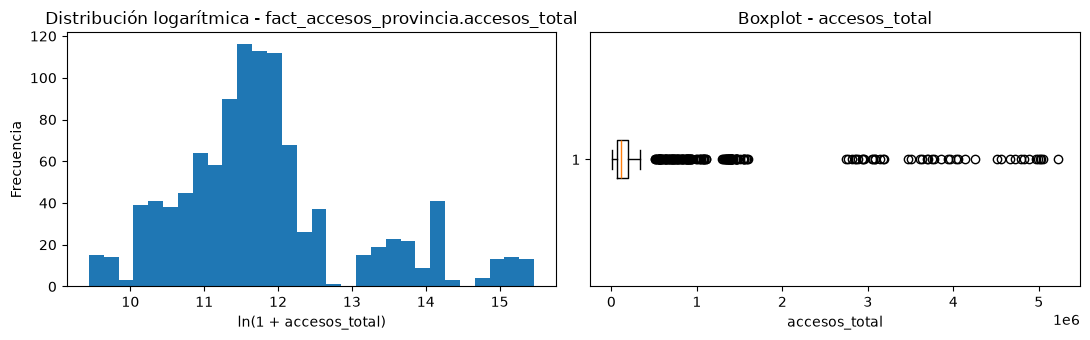

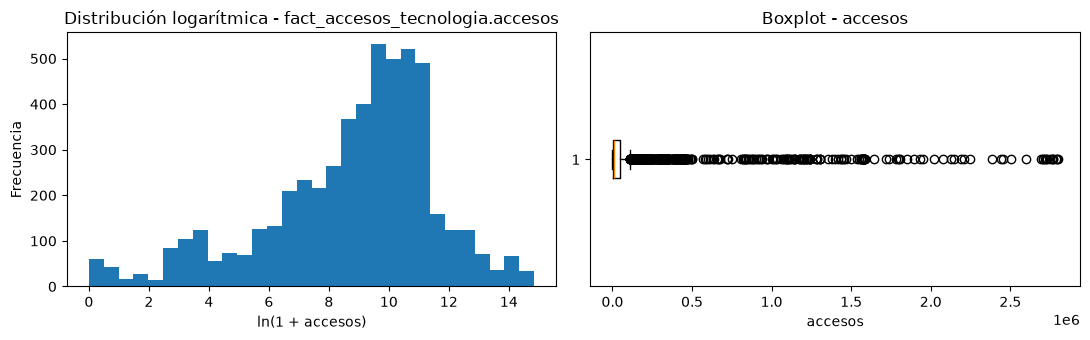

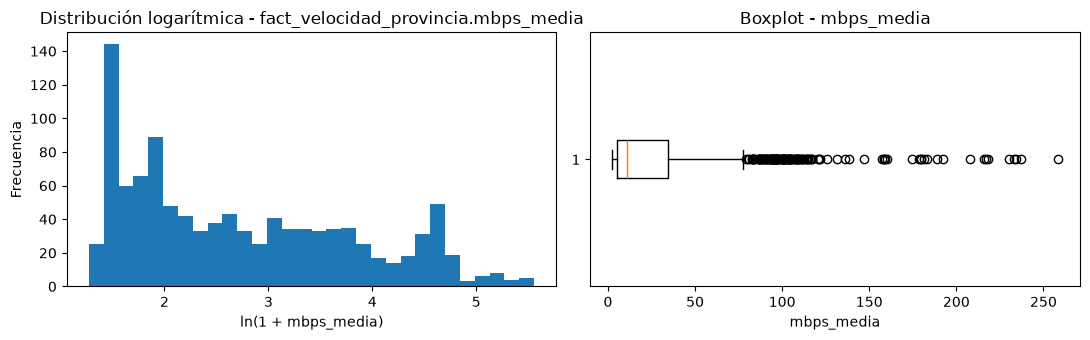

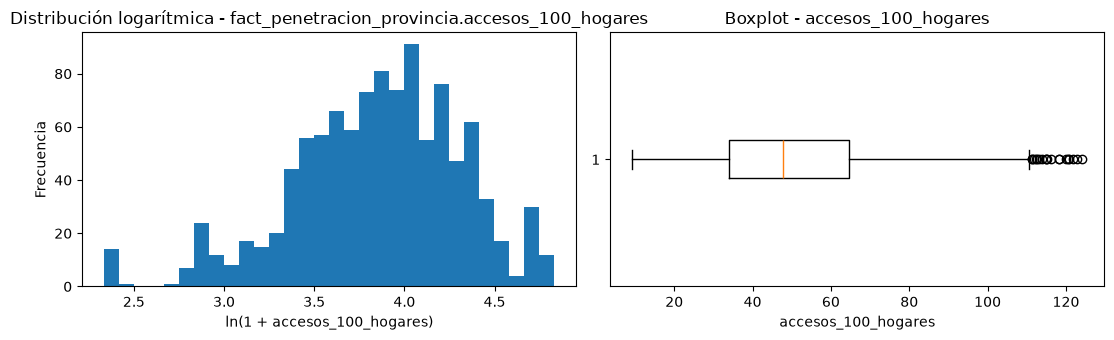

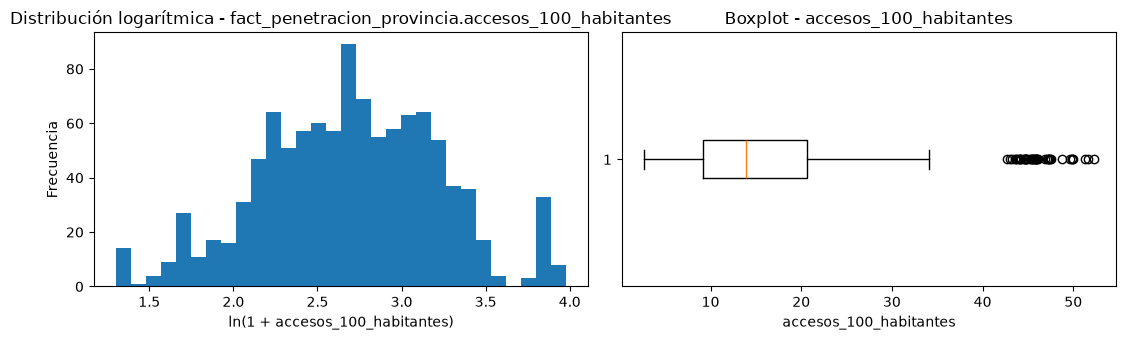

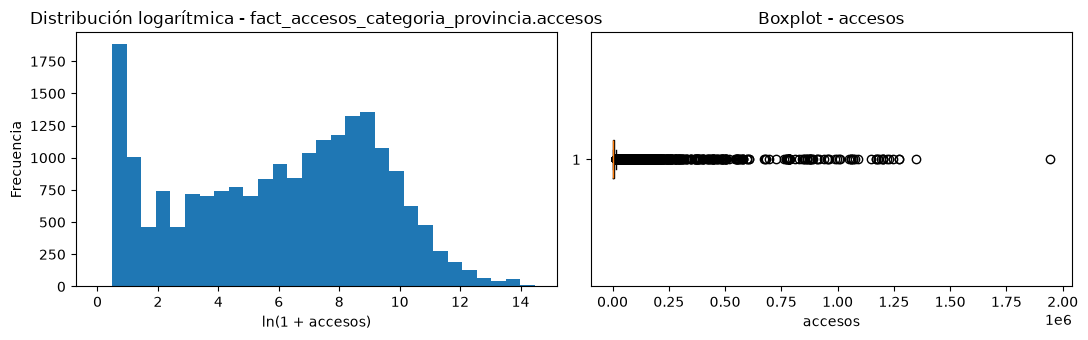

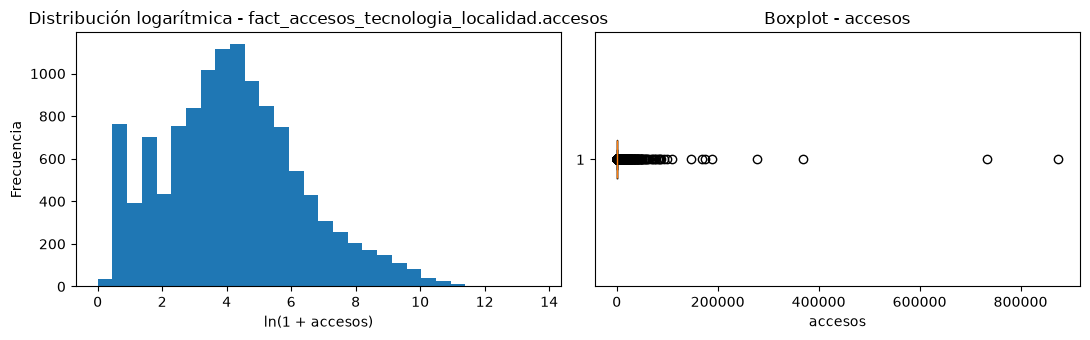

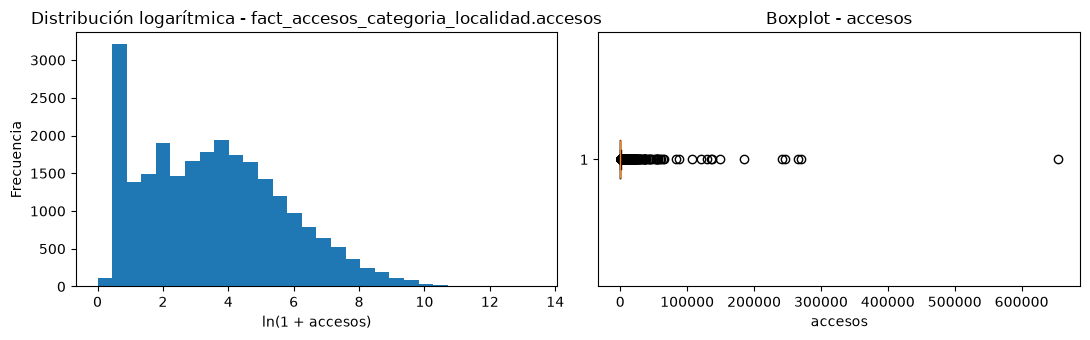

In [13]:
EXCLUIR = {
    "provincia_id",
    "tecnologia_id",
    "categoria_velocidad_id",
    "localidad_id",
    "source_row",
    "anio",
    "trimestre"
}

for t, df in data.items():

    numeric_cols = [
        c for c in df.select_dtypes(include="number").columns
        if c.lower() not in EXCLUIR
    ]

    for c in numeric_cols:
        s = df[c].dropna()

        if s.empty:
            continue

        fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

        axes[0].hist(np.log1p(s), bins=30)
        axes[0].set_title(f"Distribución logarítmica - {t}.{c}")
        axes[0].set_xlabel(f"ln(1 + {c})")
        axes[0].set_ylabel("Frecuencia")

        axes[1].boxplot(s, orientation="horizontal")
        axes[1].set_title(f"Boxplot - {c}")
        axes[1].set_xlabel(c)

        plt.tight_layout()
        plt.show()

### Interpretación de las distribuciones numéricas

Los histogramas y diagramas de caja muestran diferencias importantes en la distribución de las variables de conectividad fija en Argentina.

**Accesos:** presentan una marcada asimetría positiva, con numerosas observaciones de valores relativamente bajos y algunas considerablemente superiores. Este comportamiento es especialmente pronunciado en los datos desagregados por localidad.

**Transformación logarítmica:** debido a la elevada asimetría, se utilizó `np.log1p()` en el histograma de accesos provinciales para mejorar su visualización. Esta transformación comprime los valores elevados sin modificar los datos originales. Los boxplots mantienen la escala original.

**Velocidad media:** presenta una distribución asimétrica hacia la derecha, con predominio de velocidades relativamente bajas y algunas observaciones elevadas. Debe considerarse que se incluyen registros de distintos períodos entre 2014 y 2024.

**Penetración:** los accesos por cada 100 hogares y habitantes presentan distribuciones menos asimétricas que los accesos absolutos, lo que permite observar diferencias en el comportamiento de estos indicadores relativos.

**Valores atípicos:** los diagramas de caja identifican numerosas observaciones extremas, principalmente en las variables de accesos. Estas no representan necesariamente errores y serán analizadas posteriormente mediante el método IQR.

**Conclusión:** las distribuciones evidencian heterogeneidad en los indicadores de conectividad. Sin embargo, para determinar si existen desigualdades territoriales persistentes es necesario complementar este análisis con comparaciones provinciales y temporales.

## 8. Análisis de variables categóricas

Se identifican las variables categóricas y se calculan sus frecuencias, porcentajes y cantidad de valores distintos. Para variables con numerosas categorías se muestran las 20 más frecuentes. Las frecuencias representan cantidades de registros y no deben interpretarse como cantidades de accesos.

In [14]:
categorical_summary = []
for t, df in data.items():
    for c in df.select_dtypes(include=["object", "category", "str"]).columns:
        s = df[c].fillna("(nulo)").astype(str)
        categorical_summary.append({
            "tabla": t, "variable": c,
            "categorias_distintas": s.nunique(),
            "categoria_mas_frecuente": s.value_counts().index[0] if len(s) else None,
            "frecuencia_maxima": int(s.value_counts().iloc[0]) if len(s) else 0
        })
        print(f"\n{t}.{c} – {s.nunique()} categorías")
        display((s.value_counts().head(20).rename("frecuencia")
                 .to_frame().assign(porcentaje=lambda x: x["frecuencia"]/len(s)*100)))
display(pd.DataFrame(categorical_summary))



fact_accesos_provincia.provincia – 24 categorías


,frecuencia,porcentaje
provincia,,
Buenos Aires,44,4.167
CABA,44,4.167
Catamarca,44,4.167
Chaco,44,4.167
Chubut,44,4.167
Córdoba,44,4.167
Corrientes,44,4.167
Entre Ríos,44,4.167
Formosa,44,4.167



fact_accesos_tecnologia.provincia – 24 categorías


,frecuencia,porcentaje
provincia,,
Buenos Aires,220,4.167
CABA,220,4.167
Catamarca,220,4.167
Chaco,220,4.167
Chubut,220,4.167
Córdoba,220,4.167
Corrientes,220,4.167
Entre Ríos,220,4.167
Formosa,220,4.167



fact_accesos_tecnologia.tecnologia – 5 categorías


,frecuencia,porcentaje
tecnologia,,
ADSL,1056,20.000
Cablemodem,1056,20.000
Fibra Optica,1056,20.000
Wireless,1056,20.000
Otros,1056,20.000


... (5 outputs left out)

,frecuencia,porcentaje
provincia,,
Buenos Aires,1897,9.148
CABA,1434,6.915
Córdoba,1426,6.877
Santa Fe,1231,5.936
Río Negro,916,4.417
Mendoza,913,4.403
La Pampa,882,4.253
Misiones,851,4.104
Entre Ríos,832,4.012



fact_accesos_categoria_provincia.categoria_velocidad – 207 categorías


,frecuencia,porcentaje
categoria_velocidad,,
"0,51",696,3.356
6,673,3.245
"6,4",627,3.024
"10,1",627,3.024
"3,2",624,3.009
"1,2",623,3.004
31,620,2.990
16,617,2.975
"20,5",615,2.966


,tabla,variable,categorias_distintas,categoria_mas_frecuente,frecuencia_maxima
0,fact_accesos_provincia,provincia,24,Buenos Aires,44
1,fact_accesos_tecnologia,provincia,24,Buenos Aires,220
2,fact_accesos_tecnologia,tecnologia,5,ADSL,1056
3,fact_velocidad_provincia,provincia,24,Buenos Aires,44
4,fact_penetracion_provincia,provincia,24,Buenos Aires,44
5,fact_accesos_categoria_provincia,provincia,24,Buenos Aires,1897
6,fact_accesos_categoria_provincia,categoria_velocidad,207,"0,51",696


### Interpretación de las variables categóricas

El análisis de frecuencias permite identificar la composición y representación de las variables categóricas presentes en las tablas de hechos.

**Provincias:** las principales tablas provinciales presentan una distribución uniforme de registros entre las 24 jurisdicciones, con 44 observaciones por provincia, correspondientes al período 2014–2024.

**Tecnologías:** se identifican cinco categorías (ADSL, Cablemodem, Fibra Optica, Wireless y Otros), cada una con 1.056 registros. Esta distribución uniforme corresponde a la estructura de los datos y no implica una participación equivalente en la cantidad de accesos.

**Categorías de velocidad:** se identifican 207 etiquetas diferentes, con frecuencias variables entre categorías y provincias. Esta diversidad refleja una mayor desagregación de la información y requiere conservar las etiquetas originales para evitar interpretaciones incorrectas.

**Conclusión:** el análisis permite verificar la representación de provincias y tecnologías, además de identificar diferencias en la estructura de las categorías de velocidad. Para evaluar la participación real de cada tecnología o categoría será necesario analizar las cantidades de accesos asociadas, y no solamente la frecuencia de los registros.

## 9. Evolución temporal de accesos totales

### Objetivo del análisis temporal

Se analiza la evolución trimestral de los accesos a Internet fijo en Argentina entre 2014 y 2024, utilizando la tabla `fact_accesos_provincia`.

Los accesos se agrupan por año y trimestre para obtener el total nacional de cada período, permitiendo identificar tendencias de crecimiento y variaciones a lo largo del tiempo.

,anio,trimestre,accesos_total,periodo
0,2014,1,6398398,2014-T1
1,2014,2,6464468,2014-T2
2,2014,3,6595271,2014-T3
3,2014,4,6598496,2014-T4
4,2015,1,6737732,2015-T1
5,2015,2,6816188,2015-T2
6,2015,3,6935068,2015-T3
7,2015,4,6984831,2015-T4
8,2016,1,6907356,2016-T1
9,2016,2,7130079,2016-T2


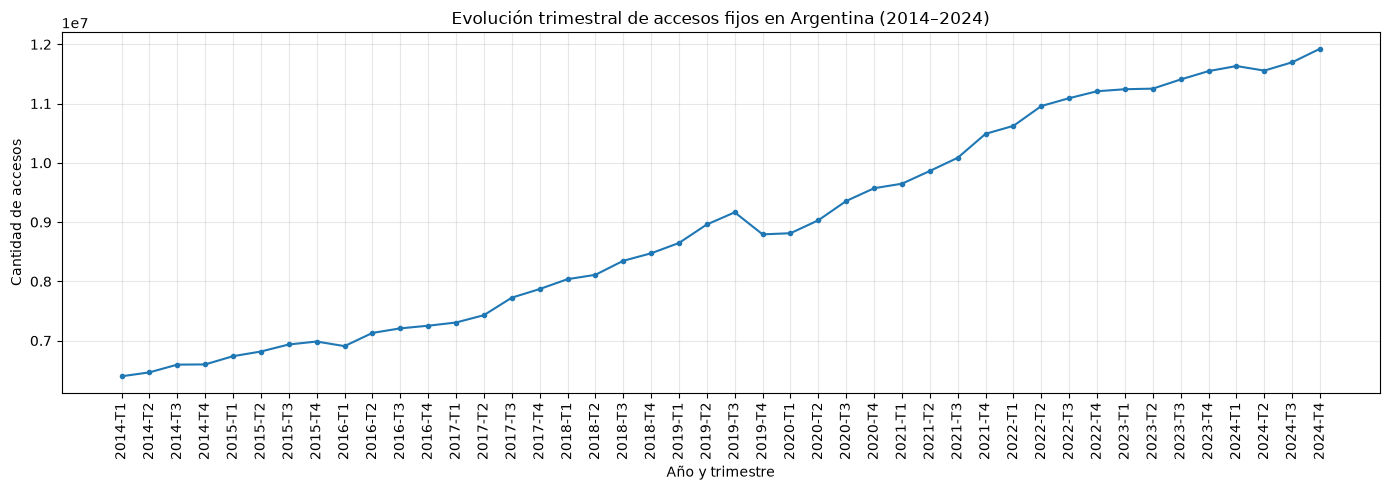

In [28]:

if "fact_accesos_provincia" in data:

    df = data["fact_accesos_provincia"].copy()

    temporal = (
        df.groupby(["anio", "trimestre"], as_index=False)
          ["accesos_total"].sum()
          .sort_values(["anio", "trimestre"])
    )

    temporal["periodo"] = (
        temporal["anio"].astype(str)
        + "-T"
        + temporal["trimestre"].astype(str)
    )

    display(temporal)

    plt.figure(figsize=(14, 5))

    plt.plot(
        temporal["periodo"],
        temporal["accesos_total"],
        marker="o",
        markersize=3
    )

    plt.title("Evolución trimestral de accesos fijos en Argentina (2014–2024)")
    plt.xlabel("Año y trimestre")
    plt.ylabel("Cantidad de accesos")
    plt.xticks(rotation=90)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("No se encontró fact_accesos_provincia.")


### Interpretación de la evolución temporal

Los accesos a Internet fijo en Argentina muestran una tendencia general creciente entre 2014 y 2024, pasando de **6.398.398 conexiones en 2014-T1 a 11.925.620 en 2024-T4**, lo que representa un incremento acumulado aproximado del **86,39%**.

Aunque se observan algunas disminuciones trimestrales, como en 2019-T4 y 2024-T2, estas no modifican la tendencia de crecimiento del período completo.

El aumento de accesos evidencia una expansión de la conectividad fija a nivel nacional. Sin embargo, este crecimiento no implica necesariamente una reducción de las desigualdades territoriales, ya que los totales nacionales no permiten identificar cómo se distribuyeron las conexiones entre provincias.

Por ello, el análisis se complementará con indicadores provinciales de penetración, velocidad y composición tecnológica.

## 10. Transformación tecnológica y participación de fibra

### Objetivo del análisis tecnológico

Se analiza la evolución de los accesos a Internet fijo según la tecnología de conexión entre 2014 y 2024, utilizando la tabla `fact_accesos_tecnologia`.

Los registros se agrupan por año, trimestre y tecnología para visualizar los cambios en la composición de los accesos y calcular la participación porcentual de la fibra óptica sobre el total de accesos clasificados por tecnología en cada período.

tecnologia,ADSL,Cablemodem,Fibra Optica,Otros,Wireless
periodo,,,,,
2022-T3,1395277,6031970,2871541,235230,557110
2022-T4,1315373,6037457,3060575,221740,572969
2023-T1,1204417,6002582,3243411,214838,576647
2023-T2,1006509,5997149,3463988,202428,581823
2023-T3,897895,6018832,3708718,200027,581436
2023-T4,836390,6022532,3908183,194796,585760
2024-T1,774475,5986957,4015101,257941,598682
2024-T2,733491,5867504,4169958,191957,593197
2024-T3,721676,5787585,4315339,264037,608325


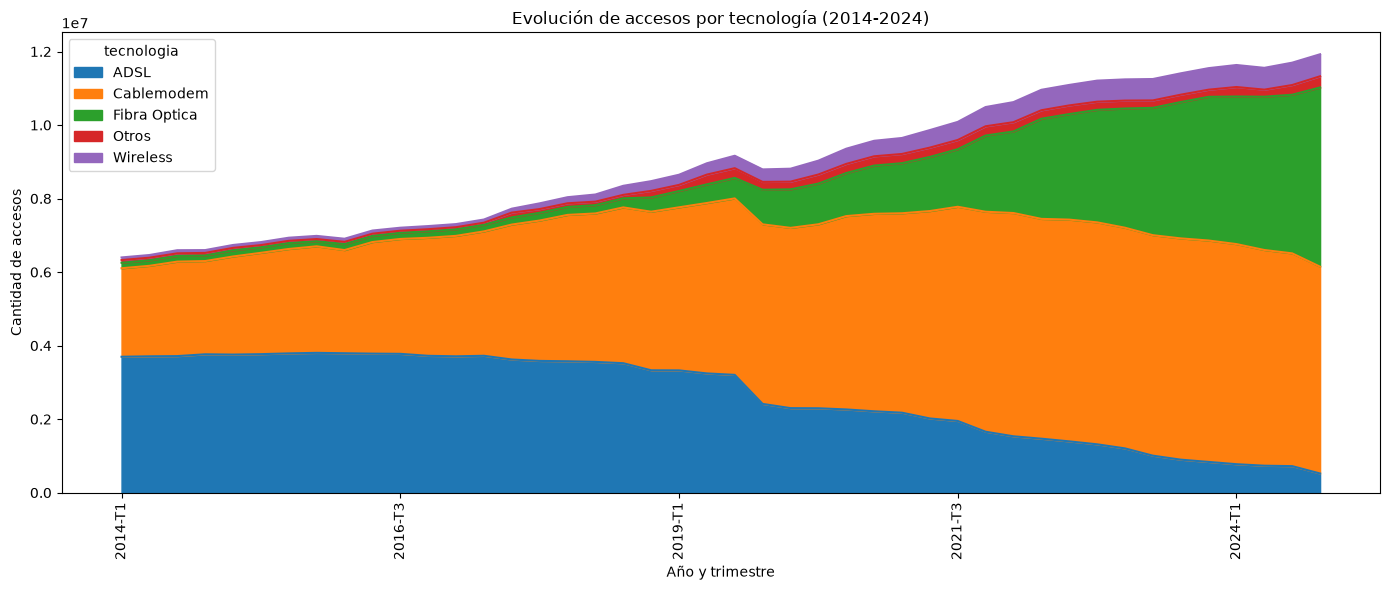

,participacion_fibra_pct
periodo,
2014-T1,2.349
2014-T2,2.311
2014-T3,2.358
2014-T4,2.268
2015-T1,2.496
2015-T2,2.213
2015-T3,2.346
2015-T4,1.993
2016-T1,2.380


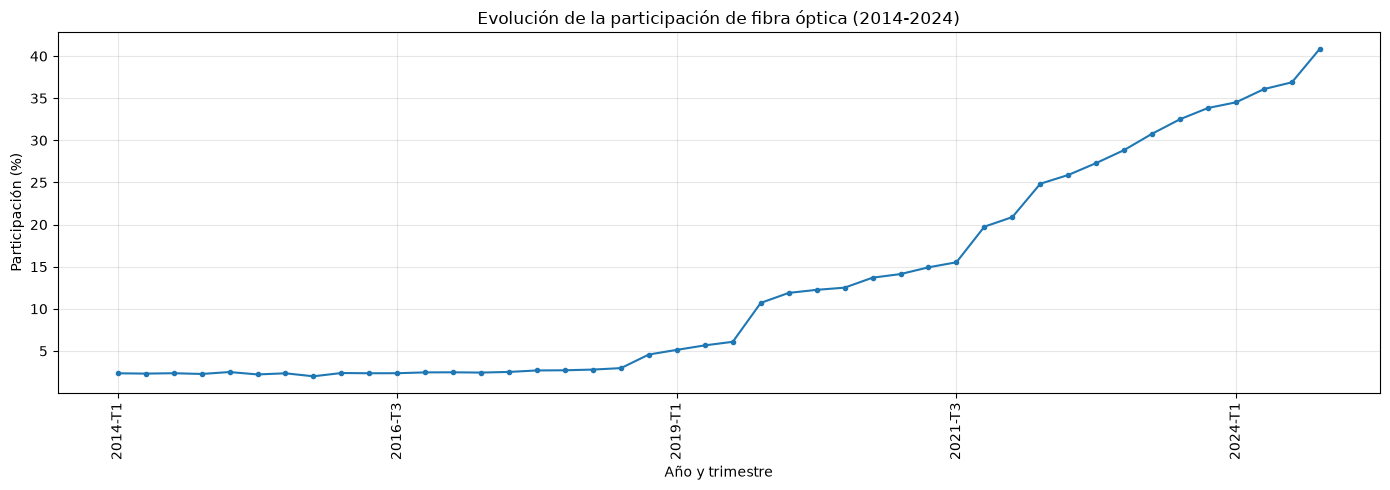

In [55]:
if "fact_accesos_tecnologia" in data:
    df = data["fact_accesos_tecnologia"].copy()

    # Agrupar por año, trimestre y tecnología
    tech_time = (
        df.groupby(["anio", "trimestre", "tecnologia"], as_index=False)
        ["accesos"].sum()
        .sort_values(["anio", "trimestre"])
    )

    # Crear etiqueta temporal
    tech_time["periodo"] = (
        tech_time["anio"].astype(str)
        + "-T" +
        tech_time["trimestre"].astype(str)
    )

    # Tabla de accesos por tecnología y período
    pivot = tech_time.pivot_table(
        index="periodo",
        columns="tecnologia",
        values="accesos",
        aggfunc="sum",
        fill_value=0
    )

    display(pivot.tail(10))

    # Gráfico de composición tecnológica
    pivot.plot(
        kind="area",
        stacked=True,
        figsize=(14, 6)
    )

    plt.title("Evolución de accesos por tecnología (2014-2024)")
    plt.xlabel("Año y trimestre")
    plt.ylabel("Cantidad de accesos")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

    # Participación de fibra óptica
    fiber_share = (
    pivot["Fibra Optica"]
    / pivot.sum(axis=1)
    * 100
    )

    display(
        fiber_share.rename("participacion_fibra_pct").to_frame()
    )

    plt.figure(figsize=(14, 5))
    fiber_share.plot(marker="o", markersize=3)

    plt.title("Evolución de la participación de fibra óptica (2014-2024)")
    plt.xlabel("Año y trimestre")
    plt.ylabel("Participación (%)")
    plt.xticks(rotation=90)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### Interpretación de la transformación tecnológica

El análisis evidencia una transformación significativa en la composición tecnológica de la conectividad fija en Argentina entre 2014 y 2024.

**Fibra óptica:** su participación pasó del 2,35% en 2014-T1 al 40,88% en 2024-T4, lo que representa un incremento de aproximadamente 38,53 puntos porcentuales. El crecimiento se intensificó especialmente a partir de 2019.

**ADSL y Cablemodem:** ADSL muestra una disminución sostenida de accesos, mientras que Cablemodem conserva un volumen importante durante el período, aunque pierde participación relativa frente al crecimiento de la fibra óptica.

**Otras tecnologías:** Wireless y Otros mantienen una presencia menor dentro del total de conexiones.

**Conclusión:** los resultados evidencian una transición hacia tecnologías de conexión más modernas, particularmente la fibra óptica. Sin embargo, este crecimiento nacional no permite determinar si la modernización tecnológica ocurrió de manera uniforme entre las provincias, por lo que será necesario complementar el análisis con comparaciones territoriales.

## 11. Brechas provinciales de penetración

### Objetivo del análisis territorial

Se comparan los indicadores de penetración de Internet fijo entre las 24 jurisdicciones argentinas durante el último período disponible (2024-T4), utilizando la tabla `fact_penetracion_provincia`.

Se analizan los accesos cada 100 hogares y cada 100 habitantes para identificar diferencias territoriales y cuantificar las brechas entre las jurisdicciones con mayores y menores valores.

Estos indicadores representan relaciones entre accesos y población u hogares, por lo que no equivalen necesariamente al porcentaje de personas u hogares únicos conectados.

Período analizado: 2024-T4
Provincias encontradas: 24
Registros encontrados: 24


,provincia,accesos_100_hogares,accesos_100_habitantes
0,CABA,105.260,47.420
1,San Luis,96.010,32.880
2,Tierra del Fuego,88.490,31.560
3,La Pampa,87.170,34.120
4,Buenos Aires,86.710,29.940
5,Chubut,82.860,30.110
6,Córdoba,77.180,28.030
7,Neuquén,73.760,26.720
8,Santa Cruz,69.970,24.750
9,Santa Fe,67.830,24.680


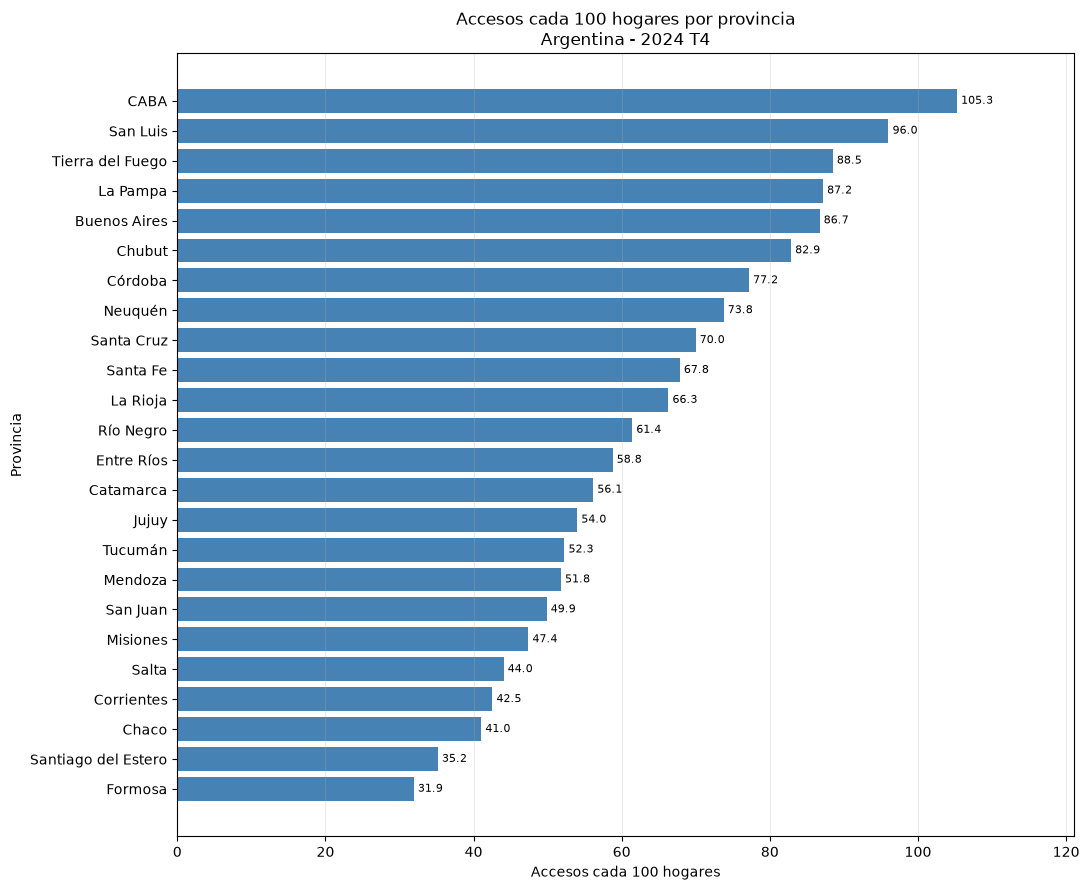

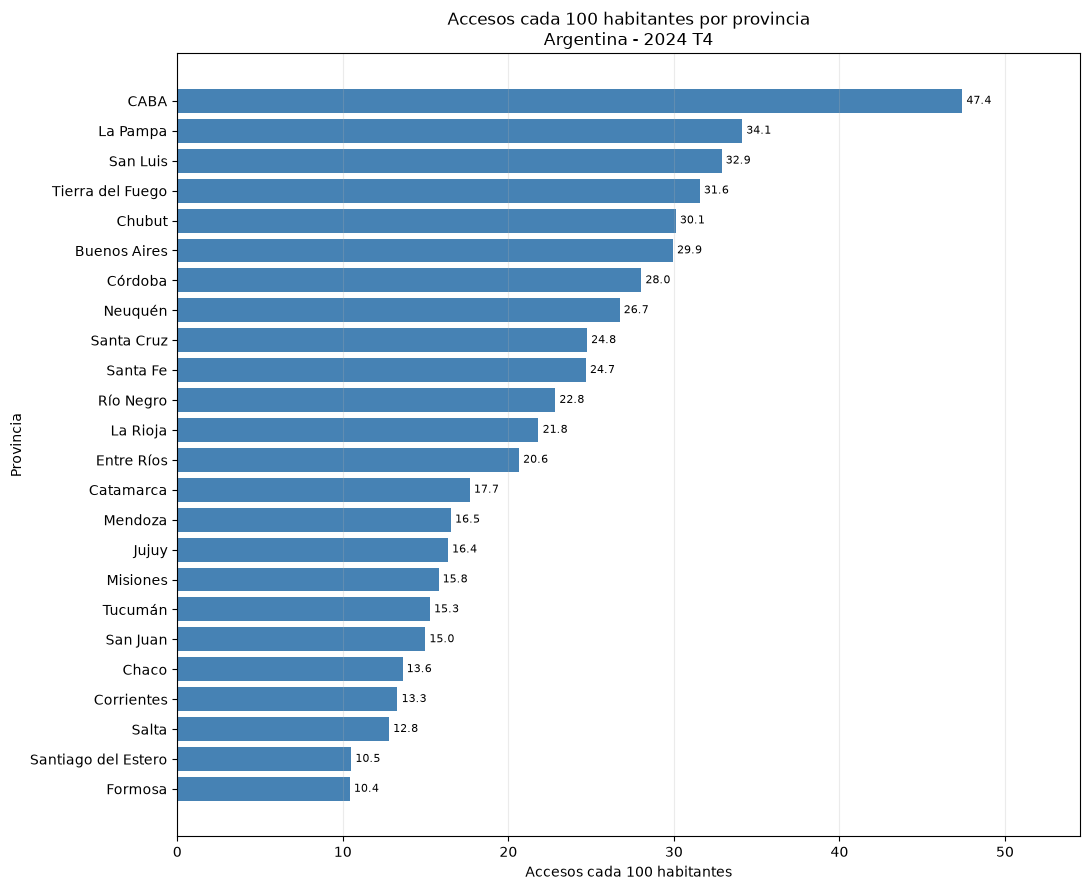


RESUMEN DE BRECHAS PROVINCIALES

Accesos cada 100 hogares:
Mayor: CABA (105.26)
Menor: Formosa (31.92)
Brecha absoluta: 73.34

Accesos cada 100 habitantes:
Mayor: CABA (47.42)
Menor: Formosa (10.42)
Brecha absoluta: 37.00


In [16]:

# 11. Brechas provinciales de penetración

if "fact_penetracion_provincia" in data:

    df = data["fact_penetracion_provincia"].copy()

    # Identificar el último año y trimestre disponibles
    ultimo_periodo = (
        df[["anio", "trimestre"]]
        .drop_duplicates()
        .sort_values(["anio", "trimestre"])
        .iloc[-1]
    )

    ultimo_anio = int(ultimo_periodo["anio"])
    ultimo_trimestre = int(ultimo_periodo["trimestre"])

    # Filtrar únicamente el último período
    latest = df[
        (df["anio"] == ultimo_anio) &
        (df["trimestre"] == ultimo_trimestre)
    ].copy()

    # Columnas a analizar
    metricas = {
        "accesos_100_hogares": "Accesos cada 100 hogares",
        "accesos_100_habitantes": "Accesos cada 100 habitantes"
    }

    print(f"Período analizado: {ultimo_anio}-T{ultimo_trimestre}")
    print(f"Provincias encontradas: {latest['provincia'].nunique()}")
    print(f"Registros encontrados: {len(latest)}")

    # Verificar que haya una fila por provincia
    if latest["provincia"].duplicated().any():
        raise ValueError(
            "Hay provincias duplicadas en el último período. "
            "Revisar la granularidad de los datos."
        )

    # Mostrar tabla comparativa
    display(
        latest[
            ["provincia"] + list(metricas.keys())
        ].sort_values(
            "accesos_100_hogares",
            ascending=False
        ).reset_index(drop=True)
    )

    # Generar gráficos comparativos
    for columna, descripcion in metricas.items():

        ranking = latest.sort_values(
            columna,
            ascending=True
        )

        plt.figure(figsize=(11, 9))

        barras = plt.barh(
            ranking["provincia"],
            ranking[columna],
            color="steelblue"
        )

        plt.bar_label(
            barras,
            fmt="%.1f",
            padding=3,
            fontsize=8
        )

        plt.title(
            f"{descripcion} por provincia\n"
            f"Argentina - {ultimo_anio} T{ultimo_trimestre}"
        )

        plt.xlabel(descripcion)
        plt.ylabel("Provincia")
        plt.xlim(0, ranking[columna].max() * 1.15)
        plt.grid(axis="x", alpha=0.25)

        plt.tight_layout()
        plt.show()

    # Resumen de brechas provinciales
    print("\nRESUMEN DE BRECHAS PROVINCIALES")

    for columna, descripcion in metricas.items():

        ranking = latest.sort_values(
            columna,
            ascending=False
        )

        mayor = ranking.iloc[0]
        menor = ranking.iloc[-1]

        brecha = mayor[columna] - menor[columna]

        print(f"\n{descripcion}:")
        print(
            f"Mayor: {mayor['provincia']} "
            f"({mayor[columna]:.2f})"
        )
        print(
            f"Menor: {menor['provincia']} "
            f"({menor[columna]:.2f})"
        )
        print(f"Brecha absoluta: {brecha:.2f}")



### Interpretación de las brechas provinciales de penetración

Los indicadores de penetración correspondientes al cuarto trimestre de 2024 evidencian diferencias significativas en la conectividad fija entre las jurisdicciones argentinas.

**Accesos cada 100 hogares:** CABA presenta el valor más alto (105,26), mientras que Formosa registra el menor (31,92), con una brecha absoluta de 73,34 accesos cada 100 hogares.

**Accesos cada 100 habitantes:** CABA también lidera este indicador (47,42), mientras que Formosa presenta el menor valor (10,42), con una diferencia de 37 accesos cada 100 habitantes.

Estas diferencias muestran una distribución territorial desigual de la penetración de Internet fijo. Los valores superiores a 100 accesos por cada 100 hogares no representan necesariamente errores, ya que pueden existir múltiples conexiones asociadas a una misma unidad residencial.

**Conclusión:** los resultados confirman la existencia de brechas territoriales de penetración en 2024. Sin embargo, para determinar si estas desigualdades se redujeron o ampliaron entre 2014 y 2024, sería necesario comparar los indicadores provinciales a lo largo del período estudiado.

### 11.1. Evolución temporal de las brechas provinciales de penetración

Se analiza la evolución de las diferencias de penetración de Internet fijo entre las provincias argentinas durante el período 2014–2024, utilizando la tabla `fact_penetracion_provincia`.

Para cada trimestre se calculan dos indicadores: la **brecha absoluta entre los valores máximos y mínimos** y el **coeficiente de variación (CV)**, que permite evaluar la dispersión relativa entre las 24 jurisdicciones.

El objetivo es determinar si las desigualdades territoriales de penetración se ampliaron, disminuyeron o se mantuvieron durante el período estudiado.

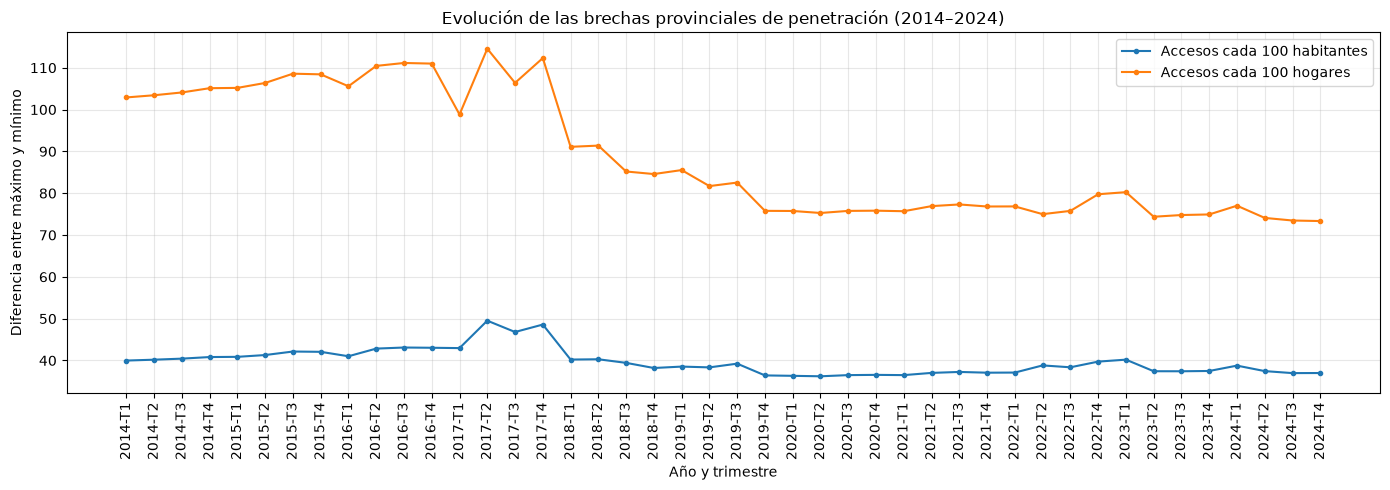

COMPARACIÓN DE BRECHAS: 2014-T1 vs. 2024-T4

Accesos cada 100 habitantes
Brecha inicial: 39.98
Brecha final: 37.00
Variación absoluta: -2.98
Resultado: la brecha disminuyó.

Accesos cada 100 hogares
Brecha inicial: 102.90
Brecha final: 73.34
Variación absoluta: -29.56
Resultado: la brecha disminuyó.


,anio,trimestre,indicador,minimo,maximo,brecha,desvio_std,periodo
78,2023,4,Accesos cada 100 hogares,30.140,105.060,74.920,19.646,2023-T4
79,2023,4,Accesos cada 100 habitantes,9.840,47.330,37.490,8.966,2023-T4
80,2024,1,Accesos cada 100 hogares,30.800,107.810,77.010,19.928,2024-T1
81,2024,1,Accesos cada 100 habitantes,10.020,48.790,38.770,9.188,2024-T1
82,2024,2,Accesos cada 100 hogares,30.890,104.980,74.090,19.865,2024-T2
83,2024,2,Accesos cada 100 habitantes,10.050,47.510,37.460,9.093,2024-T2
84,2024,3,Accesos cada 100 hogares,31.340,104.810,73.470,19.634,2024-T3
85,2024,3,Accesos cada 100 habitantes,10.230,47.210,36.980,8.999,2024-T3
86,2024,4,Accesos cada 100 hogares,31.920,105.260,73.340,20.067,2024-T4
87,2024,4,Accesos cada 100 habitantes,10.420,47.420,37.000,9.131,2024-T4


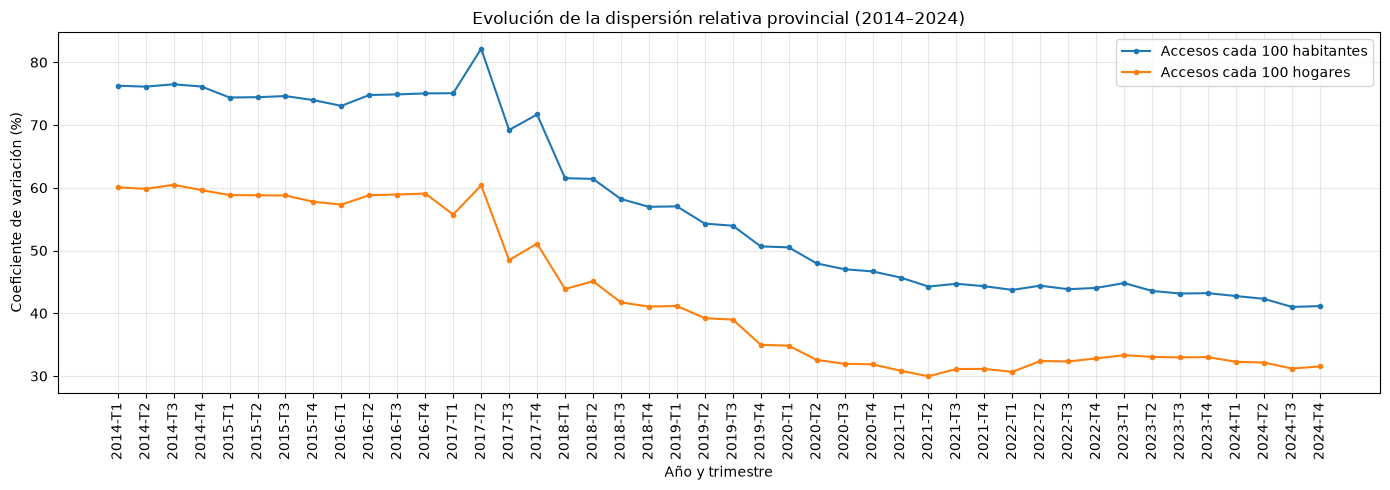

EVOLUCIÓN DEL COEFICIENTE DE VARIACIÓN

Accesos cada 100 habitantes
CV inicial: 76.26%
CV final: 41.14%
Variación: -35.12 puntos porcentuales

Accesos cada 100 hogares
CV inicial: 60.06%
CV final: 31.52%
Variación: -28.54 puntos porcentuales


In [27]:
# 11.1. Evolución temporal de las brechas provinciales

df = data["fact_penetracion_provincia"].copy()

metricas = {
    "accesos_100_hogares": "Accesos cada 100 hogares",
    "accesos_100_habitantes": "Accesos cada 100 habitantes"
}

resultados_brechas = []

for (anio, trimestre), grupo in df.groupby(["anio", "trimestre"]):

    # Verificar que cada período tenga las 24 jurisdicciones
    if grupo["provincia"].nunique() != 24 or grupo["provincia"].duplicated().any():
        raise ValueError(
            f"Período {anio}-T{trimestre}: cobertura provincial incompleta o duplicada."
        )

    for columna, descripcion in metricas.items():

        valores = grupo[columna].dropna()

        if len(valores) != 24:
            raise ValueError(
                f"Período {anio}-T{trimestre}: valores faltantes en {columna}."
            )

        resultados_brechas.append({
            "anio": anio,
            "trimestre": trimestre,
            "indicador": descripcion,
            "minimo": valores.min(),
            "maximo": valores.max(),
            "brecha": valores.max() - valores.min(),
            "desvio_std": valores.std()
        })

brechas_df = pd.DataFrame(resultados_brechas)

brechas_df = brechas_df.sort_values(
    ["anio", "trimestre"]
)

brechas_df["periodo"] = (
    brechas_df["anio"].astype(str)
    + "-T"
    + brechas_df["trimestre"].astype(str)
)

# Gráfico de evolución de brechas
plt.figure(figsize=(14, 5))

for indicador, grupo in brechas_df.groupby("indicador"):
    plt.plot(
        grupo["periodo"],
        grupo["brecha"],
        marker="o",
        markersize=3,
        label=indicador
    )

plt.title("Evolución de las brechas provinciales de penetración (2014–2024)")
plt.xlabel("Año y trimestre")
plt.ylabel("Diferencia entre máximo y mínimo")
plt.xticks(rotation=90)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Comparación del primer y último período
print("COMPARACIÓN DE BRECHAS: 2014-T1 vs. 2024-T4")

for indicador, grupo in brechas_df.groupby("indicador"):

    grupo = grupo.sort_values(["anio", "trimestre"])

    inicial = grupo.iloc[0]
    final = grupo.iloc[-1]

    variacion = final["brecha"] - inicial["brecha"]

    print(f"\n{indicador}")
    print(f"Brecha inicial: {inicial['brecha']:.2f}")
    print(f"Brecha final: {final['brecha']:.2f}")
    print(f"Variación absoluta: {variacion:+.2f}")

    if variacion > 0:
        print("Resultado: la brecha aumentó.")
    elif variacion < 0:
        print("Resultado: la brecha disminuyó.")
    else:
        print("Resultado: la brecha se mantuvo.")

display(brechas_df.tail(10))


# 11.1 - Coeficiente de variación provincial

# Calcular media y desvío estándar por período e indicador
cv_resultados = []

for columna, descripcion in metricas.items():
    estadisticas = (
        df.groupby(["anio", "trimestre"])[columna]
        .agg(["mean", "std"])
        .reset_index()
    )

    estadisticas["indicador"] = descripcion
    estadisticas["cv_pct"] = (
        estadisticas["std"] / estadisticas["mean"] * 100
    )

    cv_resultados.append(estadisticas)

cv_df = pd.concat(cv_resultados, ignore_index=True)

cv_df = cv_df.sort_values(["anio", "trimestre"])

cv_df["periodo"] = (
    cv_df["anio"].astype(str)
    + "-T"
    + cv_df["trimestre"].astype(str)
)

# Graficar evolución del coeficiente de variación
plt.figure(figsize=(14, 5))

for indicador, grupo in cv_df.groupby("indicador"):
    plt.plot(
        grupo["periodo"],
        grupo["cv_pct"],
        marker="o",
        markersize=3,
        label=indicador
    )

plt.title("Evolución de la dispersión relativa provincial (2014–2024)")
plt.xlabel("Año y trimestre")
plt.ylabel("Coeficiente de variación (%)")
plt.xticks(rotation=90)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Comparación inicial y final
print("EVOLUCIÓN DEL COEFICIENTE DE VARIACIÓN")

for indicador, grupo in cv_df.groupby("indicador"):
    grupo = grupo.sort_values(["anio", "trimestre"])

    inicial = grupo.iloc[0]
    final = grupo.iloc[-1]

    print(f"\n{indicador}")
    print(f"CV inicial: {inicial['cv_pct']:.2f}%")
    print(f"CV final: {final['cv_pct']:.2f}%")
    print(
        f"Variación: "
        f"{final['cv_pct'] - inicial['cv_pct']:+.2f} puntos porcentuales"
    )


### Interpretación de la evolución de las brechas provinciales

El análisis de los indicadores de penetración evidencia una reducción de las diferencias territoriales entre las jurisdicciones argentinas durante el período 2014–2024.

**Brechas absolutas:** la diferencia entre los valores máximos y mínimos de accesos cada 100 hogares disminuyó de 102,90 a 73,34, mientras que la brecha por cada 100 habitantes pasó de 39,98 a 37,00.

**Dispersión relativa:** el coeficiente de variación (CV) también registró una disminución significativa. Para los accesos cada 100 hogares pasó del 60,06% al 31,52%, mientras que para los accesos cada 100 habitantes se redujo del 76,26% al 41,14%.

La evolución presentó fluctuaciones trimestrales, pero ambos indicadores de dispersión muestran una reducción entre el inicio y el final del período.

**Conclusión:** los resultados aportan evidencia de una disminución de las desigualdades provinciales de penetración, tanto en términos absolutos como relativos. Sin embargo, persisten diferencias importantes en 2024, por lo que la expansión de la conectividad fija no implicó una distribución territorial completamente homogénea.

## 12. Cruces entre variables

### Objetivo del análisis provincial

Se analiza la distribución territorial de los accesos a Internet fijo en Argentina durante el último período disponible (2024-T4), utilizando la tabla `fact_accesos_provincia`.

Se relacionan las provincias con sus cantidades de accesos para elaborar un ranking de las 24 jurisdicciones y calcular su participación porcentual sobre el total nacional.

Este análisis permite identificar la concentración geográfica de las conexiones y complementar los indicadores relativos de penetración estudiados en la sección anterior.

Período analizado: 2024-T4
Provincias encontradas: 24


,provincia,accesos_total
0,Buenos Aires,5221181
1,CABA,1464187
2,Córdoba,1107308
3,Santa Fe,908776
4,Mendoza,337935
5,Entre Ríos,300845
6,Tucumán,270188
7,Misiones,211185
8,Salta,189705
9,Neuquén,187112


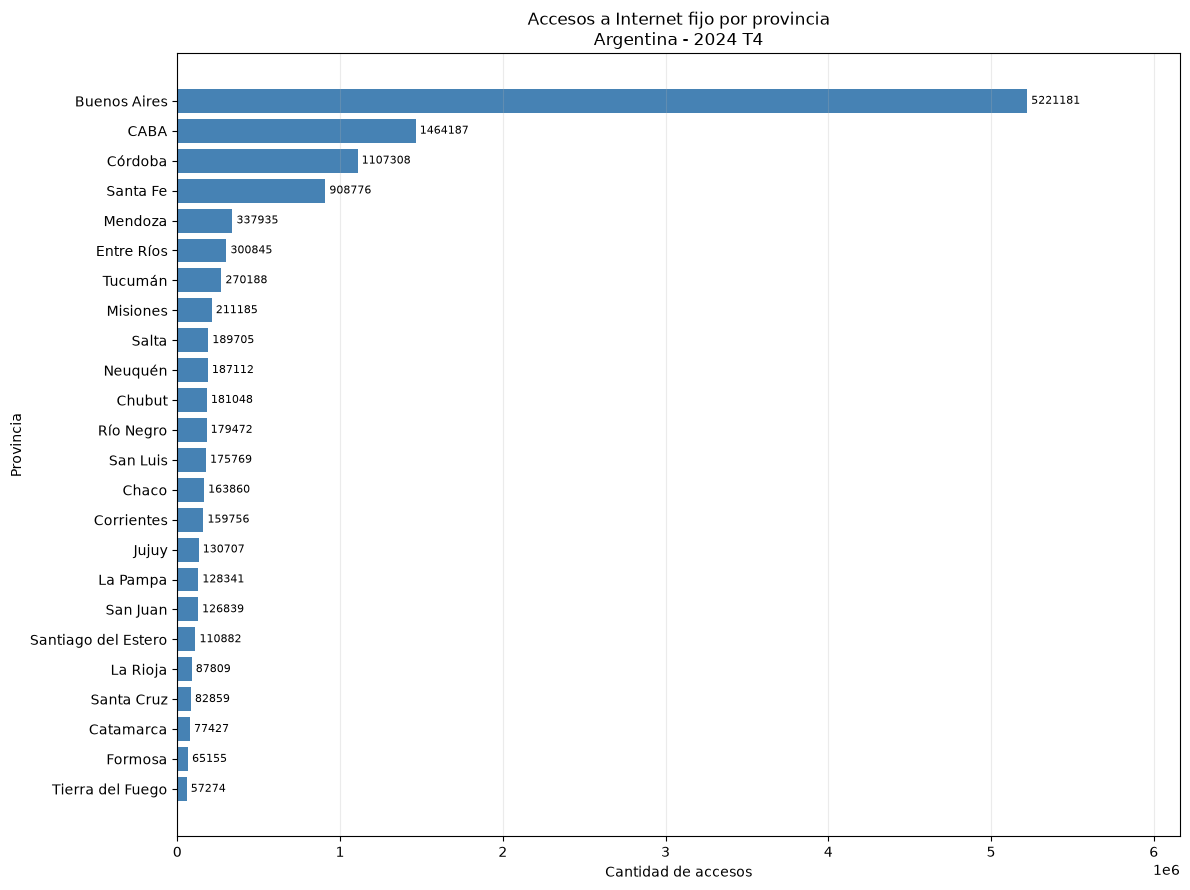


Total nacional: 11,925,620 accesos

Cinco provincias con mayor cantidad de accesos:


,provincia,accesos_total,participacion_pct
0,Buenos Aires,5221181,43.781
1,CABA,1464187,12.278
2,Córdoba,1107308,9.285
3,Santa Fe,908776,7.620
4,Mendoza,337935,2.834



Participación de las cinco primeras provincias: 75.80%


In [18]:

# 12. Cruces entre variables
# Provincia x accesos totales en el último período disponible

if "fact_accesos_provincia" in data:

    df = data["fact_accesos_provincia"].copy()

    # Identificar último período disponible
    ultimo_periodo = (
        df[["anio", "trimestre"]]
        .drop_duplicates()
        .sort_values(["anio", "trimestre"])
        .iloc[-1]
    )

    ultimo_anio = int(ultimo_periodo["anio"])
    ultimo_trimestre = int(ultimo_periodo["trimestre"])

    # Filtrar año y trimestre
    latest = df[
        (df["anio"] == ultimo_anio) &
        (df["trimestre"] == ultimo_trimestre)
    ].copy()

    # Verificar que haya una fila por provincia
    if latest["provincia"].duplicated().any():
        raise ValueError(
            "Se encontraron provincias duplicadas. "
            "Revisar la granularidad de los datos."
        )

    # Ordenar provincias por cantidad de accesos
    ranking = latest[
        ["provincia", "accesos_total"]
    ].sort_values(
        "accesos_total",
        ascending=False
    )

    print(f"Período analizado: {ultimo_anio}-T{ultimo_trimestre}")
    print(f"Provincias encontradas: {len(ranking)}")

    display(ranking.reset_index(drop=True))

    # Gráfico de accesos por provincia
    grafico = ranking.sort_values(
        "accesos_total",
        ascending=True
    )

    plt.figure(figsize=(12, 9))

    barras = plt.barh(
        grafico["provincia"],
        grafico["accesos_total"],
        color="steelblue"
    )

    plt.bar_label(
        barras,
        fmt="%.0f",
        padding=3,
        fontsize=8
    )

    plt.title(
        f"Accesos a Internet fijo por provincia\n"
        f"Argentina - {ultimo_anio} T{ultimo_trimestre}"
    )

    plt.xlabel("Cantidad de accesos")
    plt.ylabel("Provincia")
    plt.xlim(0, grafico["accesos_total"].max() * 1.18)
    plt.grid(axis="x", alpha=0.25)

    plt.tight_layout()
    plt.show()

    # Participación provincial sobre el total nacional
    total_nacional = ranking["accesos_total"].sum()

    ranking = ranking.copy()
    ranking["participacion_pct"] = (
        ranking["accesos_total"] / total_nacional * 100
    )

    print(f"\nTotal nacional: {total_nacional:,.0f} accesos")

    print("\nCinco provincias con mayor cantidad de accesos:")
    display(ranking.head(5).reset_index(drop=True))

    print(
        "\nParticipación de las cinco primeras provincias: "
        f"{ranking.head(5)['participacion_pct'].sum():.2f}%"
    )



### Interpretación de la distribución provincial de accesos

Durante el cuarto trimestre de 2024 se registraron **11.925.620 accesos a Internet fijo** en Argentina, distribuidos entre las 24 jurisdicciones analizadas.

**Concentración territorial:** Buenos Aires presenta la mayor cantidad de accesos (5.221.181), equivalente al 43,78% del total nacional. Le siguen CABA (12,28%), Córdoba (9,29%), Santa Fe (7,62%) y Mendoza (2,83%).

En conjunto, estas cinco jurisdicciones concentran el **75,80% de los accesos nacionales**, lo que evidencia una distribución desigual de las conexiones en términos absolutos.

**Relación con la penetración:** las diferencias en cantidades de accesos pueden estar asociadas, entre otros factores, al tamaño poblacional de cada jurisdicción. Por ello, una menor cantidad absoluta de conexiones no implica necesariamente una menor penetración.

**Conclusión:** los resultados muestran una elevada concentración territorial de accesos, mientras que los indicadores relativos de la sección 11 permiten evaluar las diferencias provinciales considerando la población y los hogares de cada jurisdicción.

## 13. Correlaciones e hipótesis exploratoria

Hipótesis exploratoria: **las provincias con mayor participación de fibra óptica tienden a presentar mayor velocidad media**.

- H0: no existe asociación monotónica entre participación de fibra y velocidad media provincial.
- H1: existe asociación monotónica positiva.

Se utiliza Spearman como medida principal porque no exige relación lineal. Pearson se informa como complemento. La correlación no demuestra causalidad y debe calcularse sobre provincias con ambas variables disponibles.

Período analizado: 2024-T4
Provincias incluidas: 24


,participacion_fibra_pct,velocidad_media_mbps
provincia,,
Buenos Aires,40.772,217.100
CABA,21.278,258.190
Catamarca,78.438,112.380
Chaco,54.907,114.370
Chubut,36.717,96.650
Corrientes,29.777,117.290
Córdoba,45.379,131.600
Entre Ríos,25.517,113.760
Formosa,32.564,95.120


Spearman: 0.160
Pearson: 0.049


,participacion_fibra_pct,velocidad_media_mbps
participacion_fibra_pct,1.000,0.160
velocidad_media_mbps,0.160,1.000


,participacion_fibra_pct,velocidad_media_mbps
participacion_fibra_pct,1.000,0.049
velocidad_media_mbps,0.049,1.000


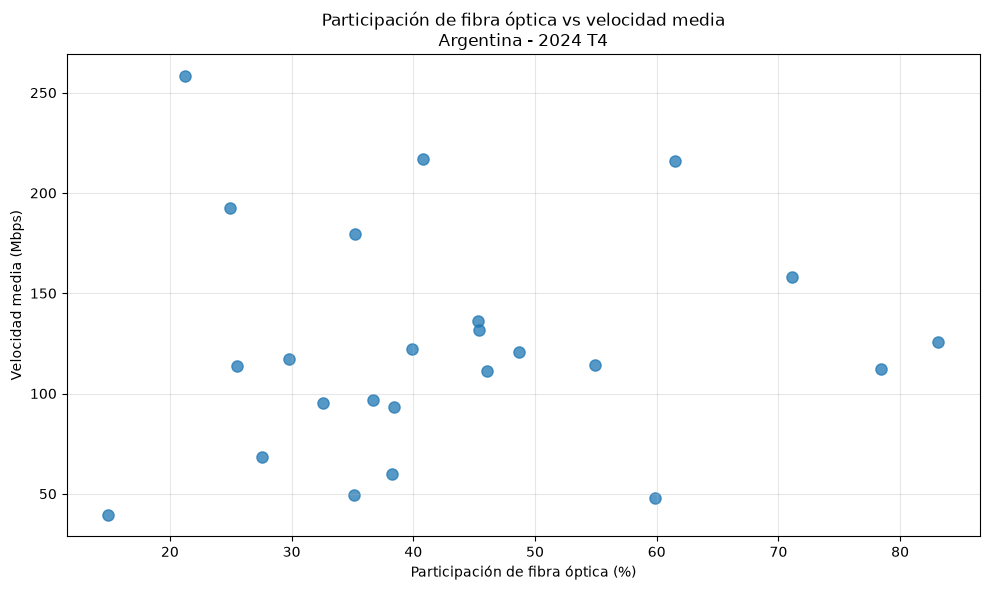

In [19]:

fiber_df = speed_df = None

if "fact_accesos_tecnologia" in data and "fact_velocidad_provincia" in data:

    ft = data["fact_accesos_tecnologia"].copy()
    fv = data["fact_velocidad_provincia"].copy()

    # Identificar el último período común entre ambas tablas
    periodos_ft = set(
        zip(ft["anio"], ft["trimestre"])
    )
    periodos_fv = set(
        zip(fv["anio"], fv["trimestre"])
    )

    periodos_comunes = periodos_ft & periodos_fv

    if not periodos_comunes:
        print("No hay períodos comunes entre ambas tablas.")

    else:
        ultimo_anio, ultimo_trimestre = max(periodos_comunes)

        print(
            f"Período analizado: "
            f"{ultimo_anio}-T{ultimo_trimestre}"
        )

        # Filtrar ambas tablas al mismo año y trimestre
        ft_last = ft[
            (ft["anio"] == ultimo_anio) &
            (ft["trimestre"] == ultimo_trimestre)
        ].copy()

        fv_last = fv[
            (fv["anio"] == ultimo_anio) &
            (fv["trimestre"] == ultimo_trimestre)
        ].copy()

        # Calcular participación de fibra por provincia
        ft_last["_es_fibra"] = (
            ft_last["tecnologia"]
            .astype(str)
            .str.contains("fibra", case=False, na=False)
        )

        agg = (
            ft_last
            .groupby(["provincia", "_es_fibra"])["accesos"]
            .sum()
            .unstack(fill_value=0)
        )

        if True not in agg.columns:
            agg[True] = 0

        if False not in agg.columns:
            agg[False] = 0

        agg["participacion_fibra_pct"] = (
            agg[True] /
            (agg[True] + agg[False]).replace(0, np.nan)
            * 100
        )

        # Velocidad media provincial del mismo período
        speed_df = (
            fv_last
            .groupby("provincia")["mbps_media"]
            .mean()
            .rename("velocidad_media_mbps")
        )

        # Unir ambas métricas por provincia
        corr_df = (
            agg[["participacion_fibra_pct"]]
            .join(speed_df, how="inner")
            .dropna()
        )

        print("Provincias incluidas:", len(corr_df))
        display(corr_df)

        if len(corr_df) >= 3:

            spearman = corr_df.corr(method="spearman").iloc[0, 1]
            pearson = corr_df.corr(method="pearson").iloc[0, 1]

            print(f"Spearman: {spearman:.3f}")
            print(f"Pearson: {pearson:.3f}")

            display(corr_df.corr(method="spearman"))
            display(corr_df.corr(method="pearson"))

            # Gráfico de dispersión
            ax = corr_df.plot.scatter(
                x="participacion_fibra_pct",
                y="velocidad_media_mbps",
                figsize=(10, 6),
                s=65,
                alpha=0.75
            )

            plt.title(
                "Participación de fibra óptica vs velocidad media\n"
                f"Argentina - {ultimo_anio} T{ultimo_trimestre}"
            )
            plt.xlabel("Participación de fibra óptica (%)")
            plt.ylabel("Velocidad media (Mbps)")
            plt.grid(alpha=0.3)
            plt.tight_layout()
            plt.show()

        else:
            print(
                "No hay suficientes provincias "
                "para calcular correlaciones."
            )

else:
    print("Faltan tablas para evaluar la hipótesis.")



### Interpretación de resultados e hipótesis exploratoria

Se analizó la relación entre la participación de fibra óptica y la velocidad media de Internet fijo en las 24 jurisdicciones de Argentina, utilizando información correspondiente al cuarto trimestre de 2024.

Los resultados muestran una correlación de Spearman de **0,160** y una correlación de Pearson de **0,049**, lo que indica una asociación positiva muy débil y una relación lineal prácticamente nula, respectivamente.

El gráfico de dispersión evidencia una considerable heterogeneidad provincial. Algunas jurisdicciones presentan velocidades medias elevadas pese a tener una participación relativamente baja de fibra óptica, mientras que otras muestran una alta participación de esta tecnología sin alcanzar velocidades equivalentes.

En consecuencia, el análisis exploratorio **no proporciona evidencia descriptiva suficiente para respaldar una asociación positiva relevante** entre ambas variables.

Estos resultados no permiten establecer relaciones causales ni demostrar la ausencia de asociación estadística. Otros factores, como la infraestructura disponible, las características de las redes, los planes comercializados y las diferencias territoriales, podrían contribuir a explicar las variaciones observadas.

**Conclusión exploratoria:** la participación de fibra óptica, considerada de manera aislada, no explica claramente las diferencias de velocidad media entre provincias durante el período analizado.

## 14. Detección de outliers mediante rango intercuartílico (IQR)

Se aplica el método del rango intercuartílico (IQR) para identificar posibles valores atípicos en las principales variables numéricas del conjunto de datos.

Para las tablas con información temporal, el análisis se realiza por año y trimestre, evitando comparar directamente observaciones correspondientes a diferentes períodos históricos.

Se excluyen identificadores y campos técnicos, considerando únicamente métricas relevantes como accesos, velocidad media y penetración.

Los valores detectados no se eliminan, ya que pueden representar diferencias reales entre provincias, tecnologías o localidades. La identificación de outliers constituye una herramienta exploratoria y no implica necesariamente errores en los datos.

In [20]:
# 14. Detección de outliers mediante IQR

# Tablas y métricas que vamos a analizar
METRICAS_IQR = {
    "fact_accesos_provincia": ["accesos_total"],
    "fact_accesos_tecnologia": ["accesos"],
    "fact_velocidad_provincia": ["mbps_media"],
    "fact_penetracion_provincia": [
        "accesos_100_hogares",
        "accesos_100_habitantes"
    ],
    "fact_accesos_categoria_provincia": ["accesos"],
    "fact_accesos_tecnologia_localidad": ["accesos"],
    "fact_accesos_categoria_localidad": ["accesos"]
}

outlier_rows = []
outlier_details = []

for tabla, metricas in METRICAS_IQR.items():

    if tabla not in data:
        continue

    df = data[tabla].copy()

    # Analizar cada período por separado cuando existe
    if {"anio", "trimestre"}.issubset(df.columns):
        grupos = df.groupby(["anio", "trimestre"])
    else:
        grupos = [("Sin período", df)]

    for periodo, grupo in grupos:

        for metrica in metricas:

            if metrica not in grupo.columns:
                continue

            valores = pd.to_numeric(
                grupo[metrica], errors="coerce"
            ).dropna()

            if len(valores) < 4 or valores.nunique() < 3:
                continue

            q1 = valores.quantile(0.25)
            q3 = valores.quantile(0.75)
            iqr = q3 - q1

            if iqr == 0:
                continue

            limite_inferior = q1 - 1.5 * iqr
            limite_superior = q3 + 1.5 * iqr

            mascara = (
                (valores < limite_inferior) |
                (valores > limite_superior)
            )

            cantidad = int(mascara.sum())

            if isinstance(periodo, tuple):
                etiqueta = f"{periodo[0]}-T{periodo[1]}"
            else:
                etiqueta = str(periodo)

            outlier_rows.append({
                "tabla": tabla,
                "periodo": etiqueta,
                "variable": metrica,
                "registros": len(valores),
                "outliers": cantidad,
                "porcentaje_outliers": round(
                    cantidad / len(valores) * 100, 2
                ),
                "limite_inferior": round(limite_inferior, 3),
                "limite_superior": round(limite_superior, 3)
            })

            if cantidad > 0:
                detalle = grupo.loc[mascara[mascara].index].copy()
                detalle["periodo_analizado"] = etiqueta
                detalle["variable_analizada"] = metrica
                outlier_details.append(detalle)

# Resultados
outlier_summary = pd.DataFrame(outlier_rows)

if not outlier_summary.empty:

    resumen = (
        outlier_summary
        .groupby(["tabla", "variable"], as_index=False)
        .agg(
            registros=("registros", "sum"),
            outliers=("outliers", "sum")
        )
    )

    resumen["porcentaje_outliers"] = (
        resumen["outliers"] / resumen["registros"] * 100
    ).round(2)

    resumen = resumen.sort_values(
        "porcentaje_outliers", ascending=False
    )

    print("RESUMEN DE OUTLIERS POR VARIABLE")
    display(resumen)

    print("\nDETALLE POR PERÍODO")
    display(outlier_summary)

else:
    print("No se encontraron grupos suficientes para aplicar IQR.")



RESUMEN DE OUTLIERS POR VARIABLE


,tabla,variable,registros,outliers,porcentaje_outliers
2,fact_accesos_provincia,accesos_total,1056,176,16.670
0,fact_accesos_categoria_localidad,accesos,24990,3750,15.010
4,fact_accesos_tecnologia_localidad,accesos,12100,1793,14.820
1,fact_accesos_categoria_provincia,accesos,20737,2818,13.590
3,fact_accesos_tecnologia,accesos,5280,573,10.850
5,fact_penetracion_provincia,accesos_100_habitantes,1056,41,3.880
7,fact_velocidad_provincia,mbps_media,1056,30,2.840
6,fact_penetracion_provincia,accesos_100_hogares,1056,21,1.990



DETALLE POR PERÍODO


,tabla,periodo,variable,registros,outliers,porcentaje_outliers,limite_inferior,limite_superior
0,fact_accesos_provincia,2014-T1,accesos_total,24,4,16.670,"-115,710.750","279,197.250"
1,fact_accesos_provincia,2014-T2,accesos_total,24,4,16.670,"-117,363.750","283,134.250"
2,fact_accesos_provincia,2014-T3,accesos_total,24,4,16.670,"-118,589.750","284,326.250"
3,fact_accesos_provincia,2014-T4,accesos_total,24,4,16.670,"-121,784.375","294,304.625"
4,fact_accesos_provincia,2015-T1,accesos_total,24,4,16.670,"-128,281.125","309,327.875"
...,...,...,...,...,...,...,...,...
246,fact_accesos_categoria_provincia,2024-T2,accesos,874,116,13.270,"-8,049.750","13,496.250"
247,fact_accesos_categoria_provincia,2024-T3,accesos,886,116,13.090,"-8,133.250","13,638.750"
248,fact_accesos_categoria_provincia,2024-T4,accesos,967,126,13.030,"-6,645.250","11,152.750"
249,fact_accesos_tecnologia_localidad,Sin período,accesos,12100,1793,14.820,-337.000,599.000


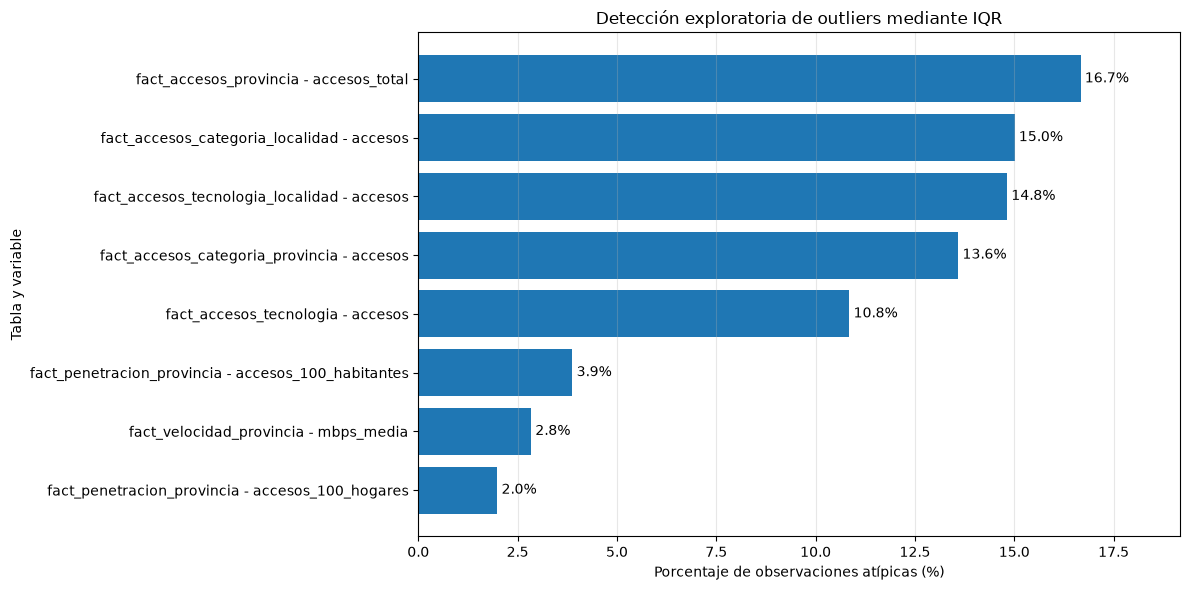

In [65]:

if not outlier_summary.empty:

    grafico = resumen.copy()
    grafico["etiqueta"] = (
        grafico["tabla"] + " - " + grafico["variable"]
    )

    grafico = grafico.sort_values("porcentaje_outliers")

    plt.figure(figsize=(12, 6))

    barras = plt.barh(
        grafico["etiqueta"],
        grafico["porcentaje_outliers"]
    )

    plt.bar_label(barras, fmt="%.1f%%", padding=3)

    plt.title("Detección exploratoria de outliers mediante IQR")
    plt.xlabel("Porcentaje de observaciones atípicas (%)")
    plt.ylabel("Tabla y variable")
    plt.xlim(
        0,
        max(grafico["porcentaje_outliers"].max() * 1.15, 1)
    )
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


### Interpretación de los resultados

El análisis mediante el rango intercuartílico (IQR) permitió identificar posibles valores atípicos en las principales variables numéricas del conjunto de datos.

La mayor proporción de observaciones atípicas se encontró en los accesos totales por provincia (16,67 %), seguida de los accesos por categoría y localidad (15,01 %) y por tecnología y localidad (14,82 %).

Estos resultados podrían estar relacionados con las diferencias de escala territorial y la concentración de conexiones en determinadas provincias y localidades.

Por otro lado, las variables de penetración y velocidad media provincial presentaron porcentajes menores de valores atípicos, entre el 1,99 % y el 3,88 %.

Para las tablas con información temporal, el análisis se realizó por año y trimestre, evitando comparar directamente observaciones de distintos períodos históricos. Las tablas sin período identificado se analizaron globalmente.

**Conclusión exploratoria:** la presencia de valores extremos no implica necesariamente errores en los datos, sino que puede reflejar desigualdades territoriales, diferencias de escala o particularidades de las tecnologías analizadas. Por este motivo, se conservaron todas las observaciones originales.

## 15. Análisis territorial de localidades (sin evolución temporal)

Se analiza la distribución territorial de los accesos a Internet fijo a nivel de localidad, utilizando las tablas `fact_accesos_tecnologia_localidad` y `fact_accesos_categoria_localidad`.

Mediante la relación con las dimensiones `dim_localidad` y `dim_provincia`, se identifican los nombres de las localidades y sus respectivas provincias.

Se construyen rankings de las 20 localidades con mayor cantidad de accesos y gráficos de barras horizontales para visualizar la concentración territorial de la conectividad.

Los resultados permiten identificar las localidades con mayor volumen de accesos a Internet fijo y comparar los totales obtenidos a partir de las tablas de tecnologías y categorías de velocidad. Se observan pequeñas diferencias entre ambas fuentes, que pueden responder a diferencias de cobertura o clasificación de los datos y requieren validación antes de atribuirles una causa.

**Limitación metodológica:** las tablas de localidades utilizadas no contienen información temporal, por lo que el análisis representa una distribución territorial y no permite evaluar la evolución histórica de los accesos a nivel local.


TOP 20 LOCALIDADES - fact_accesos_tecnologia_localidad


,localidad,provincia,accesos
0,Ciudad Autónoma de Buenos Aires,CABA,1631231
1,Córdoba,Córdoba,568595
2,Rosario,Santa Fe,357753
3,Mar del Plata,Buenos Aires,304101
4,La Plata,Buenos Aires,252382
5,Salta,Salta,212278
6,San Miguel de Tucumán (Est. Tucumán),Tucumán,188476
7,Santa Fe,Santa Fe,143625
8,Santiago del Estero,Santiago del Estero,142908
9,Bahía Blanca,Buenos Aires,139342


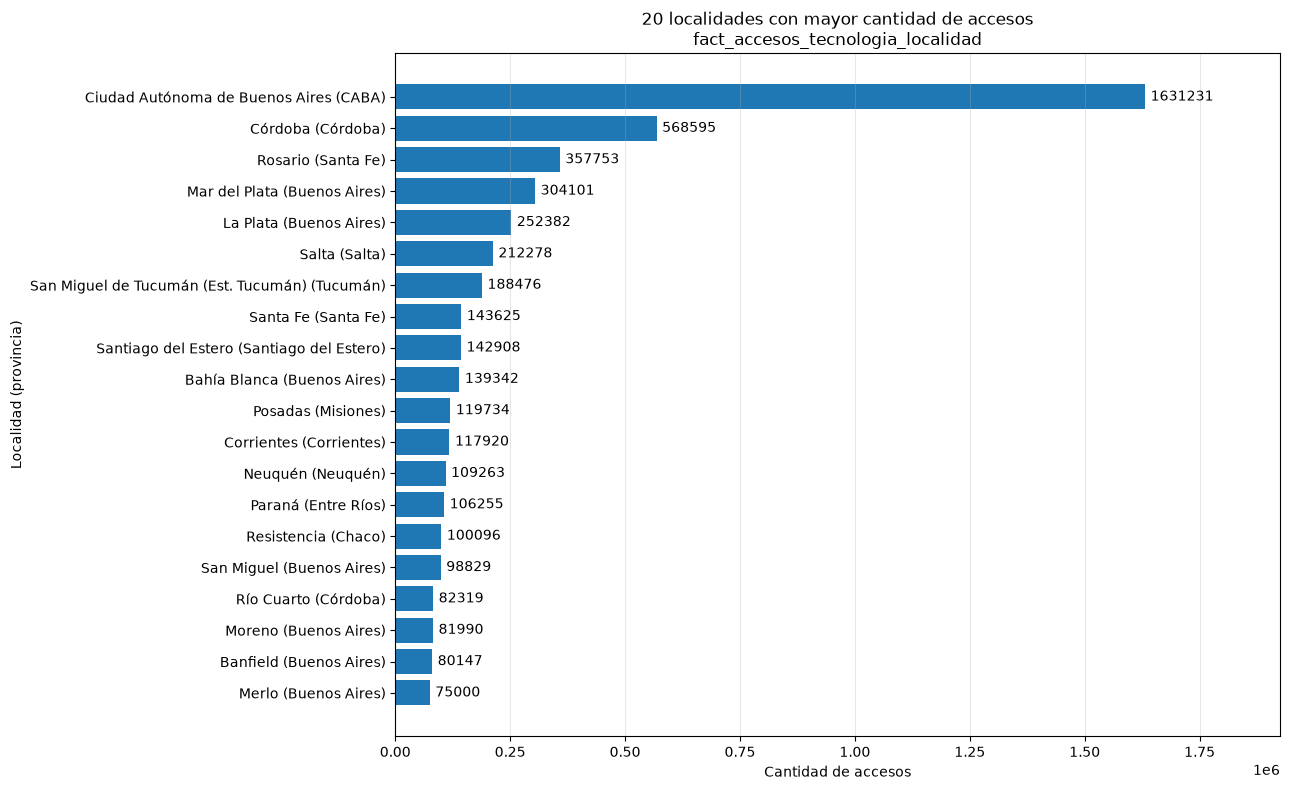


TOP 20 LOCALIDADES - fact_accesos_categoria_localidad


,localidad,provincia,accesos
0,Ciudad Autónoma de Buenos Aires,CABA,1585786
1,Córdoba,Córdoba,571966
2,Rosario,Santa Fe,353034
3,Mar del Plata,Buenos Aires,301704
4,La Plata,Buenos Aires,251433
5,Salta,Salta,194228
6,San Miguel de Tucumán (Est. Tucumán),Tucumán,187407
7,Santa Fe,Santa Fe,146486
8,Bahía Blanca,Buenos Aires,138272
9,Santiago del Estero,Santiago del Estero,120986


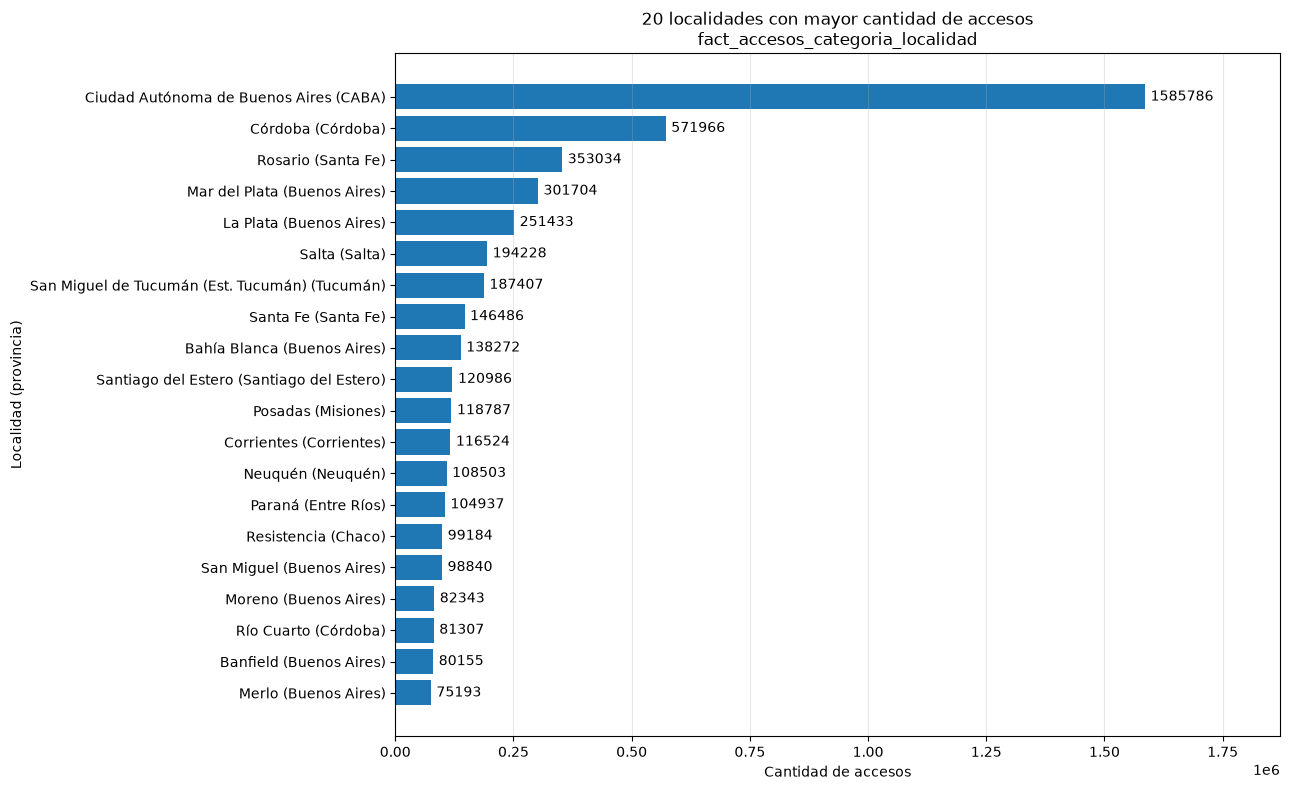

In [21]:
# 15. Análisis territorial de localidades
# Cargar dimensiones
dim_localidad = pd.read_sql_query(
    "SELECT localidad_id, provincia_id, departamento, localidad FROM dim_localidad",
    conn
)

dim_provincia = pd.read_sql_query(
    "SELECT provincia_id, provincia FROM dim_provincia",
    conn
)

# Incorporar nombre de provincia a las localidades
localidades = dim_localidad.merge(
    dim_provincia,
    on="provincia_id",
    how="left"
)

# Tablas de hechos que vamos a analizar
TABLAS_LOCALIDAD = [
    "fact_accesos_tecnologia_localidad",
    "fact_accesos_categoria_localidad"
]

for tabla in TABLAS_LOCALIDAD:

    if tabla not in data:
        continue

    df = data[tabla].copy()

    # Incorporar información territorial
    df = df.merge(
        localidades,
        on="localidad_id",
        how="left",
        validate="many_to_one"
    )

    # Agrupar accesos por localidad
    ranking = (
        df.groupby(
            ["localidad_id", "localidad", "provincia"],
            as_index=False
        )["accesos"]
        .sum()
        .sort_values("accesos", ascending=False)
        .head(20)
        .copy()
    )

    # Crear etiqueta para distinguir localidades homónimas
    ranking["ubicacion"] = (
        ranking["localidad"]
        + " (" +
        ranking["provincia"]
        + ")"
    )

    print(f"\nTOP 20 LOCALIDADES - {tabla}")
    display(
        ranking[
            ["localidad", "provincia", "accesos"]
        ].reset_index(drop=True)
    )

    # Gráfico
    grafico = ranking.sort_values("accesos")

    plt.figure(figsize=(13, 8))

    barras = plt.barh(
        grafico["ubicacion"],
        grafico["accesos"]
    )

    plt.bar_label(
        barras,
        fmt="%.0f",
        padding=4
    )

    plt.title(
        f"20 localidades con mayor cantidad de accesos\n{tabla}"
    )

    plt.xlabel("Cantidad de accesos")
    plt.ylabel("Localidad (provincia)")

    plt.xlim(
        0,
        grafico["accesos"].max() * 1.18
    )

    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


### Interpretación de los resultados

El análisis territorial evidencia una importante concentración de accesos a Internet fijo en las principales ciudades de Argentina.

La Ciudad Autónoma de Buenos Aires presenta la mayor cantidad de accesos registrados, con aproximadamente 1,63 millones según la clasificación por tecnología, seguida por Córdoba (568.595) y Rosario (357.753).

Ambas tablas analizadas presentan resultados similares y mantienen las mismas tres localidades en las primeras posiciones, aunque existen diferencias en las cantidades registradas.

También se observa una presencia destacada de localidades pertenecientes a la provincia de Buenos Aires, como Mar del Plata, La Plata, Bahía Blanca, San Miguel, Moreno, Banfield y Merlo.

Estos resultados permiten identificar una concentración territorial de conexiones en grandes centros urbanos. Sin embargo, la cantidad absoluta de accesos no permite determinar por sí sola qué localidades tienen mejor cobertura o mayor penetración, ya que no se considera su población o cantidad de hogares.

Finalmente, debido a que las tablas utilizadas no incluyen información temporal, los resultados representan una comparación territorial y no permiten analizar la evolución histórica de los accesos por localidad.

## 16. Identificación de patrones y primeras conclusiones exploratorias

En esta sección se integran los principales resultados obtenidos durante el análisis exploratorio de los datos de conectividad fija en Argentina.

Se analizan los patrones de crecimiento de los accesos a Internet fijo entre 2014 y 2024, las diferencias provinciales en los niveles de penetración, la participación de la fibra óptica y la relación exploratoria entre tecnología y velocidad media.

Para garantizar la consistencia de los resultados, los indicadores temporales se calculan considerando conjuntamente el año y el trimestre, evitando mezclar observaciones de diferentes períodos.

Las conclusiones se basan en estadísticas descriptivas y análisis exploratorios, por lo que permiten identificar tendencias y asociaciones, pero no establecer relaciones causales.

In [22]:
# 16. Identificación de patrones y primeras conclusiones exploratorias

observaciones = []

# --------------------------------------------------
# 1. Evolución temporal de accesos
# --------------------------------------------------

df = data["fact_accesos_provincia"].copy()

evolucion = (
    df.groupby(["anio", "trimestre"], as_index=False)["accesos_total"]
    .sum()
    .sort_values(["anio", "trimestre"])
)

evolucion["periodo"] = (
    evolucion["anio"].astype(str)
    + "-T"
    + evolucion["trimestre"].astype(str)
)

primero = evolucion.iloc[0]
ultimo = evolucion.iloc[-1]
maximo = evolucion.loc[evolucion["accesos_total"].idxmax()]

variacion = (
    (ultimo["accesos_total"] - primero["accesos_total"])
    / primero["accesos_total"]
    * 100
)

observaciones.append(
    f"Entre {primero['periodo']} y {ultimo['periodo']}, "
    f"los accesos aumentaron un {variacion:.2f}%."
)

observaciones.append(
    f"El máximo de accesos se registró en {maximo['periodo']}, "
    f"con {maximo['accesos_total']:,.0f} conexiones."
)

# --------------------------------------------------
# 2. Brechas provinciales de penetración
# --------------------------------------------------

df = data["fact_penetracion_provincia"].copy()

ultimo_anio = df["anio"].max()
ultimo_trimestre = df.loc[
    df["anio"] == ultimo_anio, "trimestre"
].max()

penetracion = df[
    (df["anio"] == ultimo_anio) &
    (df["trimestre"] == ultimo_trimestre)
].copy()

penetracion = penetracion.sort_values(
    "accesos_100_hogares", ascending=False
)

mayor = penetracion.iloc[0]
menor = penetracion.iloc[-1]

brecha = (
    mayor["accesos_100_hogares"]
    - menor["accesos_100_hogares"]
)

observaciones.append(
    f"En {ultimo_anio}-T{ultimo_trimestre}, "
    f"{mayor['provincia']} presentó la mayor penetración "
    f"({mayor['accesos_100_hogares']:.2f} accesos cada 100 hogares), "
    f"mientras que {menor['provincia']} registró la menor "
    f"({menor['accesos_100_hogares']:.2f}). "
    f"La brecha fue de {brecha:.2f} accesos cada 100 hogares."
)

# --------------------------------------------------
# 3. Transformación tecnológica
# --------------------------------------------------

df = data["fact_accesos_tecnologia"].copy()

ultimo_anio_tech = df["anio"].max()
ultimo_trim_tech = df.loc[
    df["anio"] == ultimo_anio_tech, "trimestre"
].max()

tecnologias = df[
    (df["anio"] == ultimo_anio_tech) &
    (df["trimestre"] == ultimo_trim_tech)
].copy()

total_tecnologias = tecnologias["accesos"].sum()

fibra = tecnologias[
    tecnologias["tecnologia"].str.contains(
        "fibra", case=False, na=False
    )
]["accesos"].sum()

participacion_fibra = fibra / total_tecnologias * 100

observaciones.append(
    f"En {ultimo_anio_tech}-T{ultimo_trim_tech}, "
    f"la fibra óptica representó el "
    f"{participacion_fibra:.2f}% de los accesos "
    f"clasificados por tecnología."
)

# --------------------------------------------------
# 4. Correlación entre fibra y velocidad
# --------------------------------------------------

if "corr_df" in globals() and len(corr_df) >= 3:

    spearman = corr_df[
        ["participacion_fibra_pct", "velocidad_media_mbps"]
    ].corr(method="spearman").iloc[0, 1]

    observaciones.append(
        f"La correlación de Spearman entre participación "
        f"de fibra óptica y velocidad media provincial "
        f"fue de {spearman:.3f}, indicando una asociación "
        f"{'positiva' if spearman > 0 else 'negativa' if spearman < 0 else 'nula'} "
        f"de magnitud {'débil' if abs(spearman) < 0.3 else 'moderada' if abs(spearman) < 0.7 else 'fuerte'}."
    )

# --------------------------------------------------
# 5. Mostrar conclusiones
# --------------------------------------------------

print("PRIMERAS CONCLUSIONES EXPLORATORIAS\n")

for i, observacion in enumerate(observaciones, 1):
    print(f"{i}. {observacion}\n")


PRIMERAS CONCLUSIONES EXPLORATORIAS

1. Entre 2014-T1 y 2024-T4, los accesos aumentaron un 86.38%.

2. El máximo de accesos se registró en 2024-T4, con 11,925,620 conexiones.

3. En 2024-T4, CABA presentó la mayor penetración (105.26 accesos cada 100 hogares), mientras que Formosa registró la menor (31.92). La brecha fue de 73.34 accesos cada 100 hogares.

4. En 2024-T4, la fibra óptica representó el 40.88% de los accesos clasificados por tecnología.

5. La correlación de Spearman entre participación de fibra óptica y velocidad media provincial fue de 0.160, indicando una asociación positiva de magnitud débil.



### Interpretación de las primeras conclusiones exploratorias

El análisis de los datos de ENACOM evidencia un crecimiento sostenido, aunque con fluctuaciones, de la conectividad fija en Argentina entre 2014 y 2024. Durante este período, la cantidad de accesos aumentó un 86,38 %, alcanzando aproximadamente 11,93 millones de conexiones en el último trimestre de 2024.

También se observa una transformación tecnológica, caracterizada por el aumento de la participación de la fibra óptica, que alcanzó el 40,88 % de los accesos clasificados por tecnología en 2024-T4.

Sin embargo, persisten diferencias territoriales importantes. CABA presenta niveles de penetración considerablemente superiores a los de provincias como Formosa, lo que evidencia desigualdades en la distribución de la conectividad.

Por otra parte, la correlación positiva débil entre la participación de fibra óptica y la velocidad media provincial indica que una mayor presencia de esta tecnología no necesariamente se corresponde con mayores velocidades promedio.

En conjunto, los resultados permiten identificar tres patrones principales: **crecimiento de los accesos, transformación tecnológica y persistencia de desigualdades territoriales**. Estas observaciones constituyen una base para profundizar el análisis mediante herramientas de visualización y análisis de datos.

## 17. Exportación de resultados

Se exportan los principales resultados del análisis exploratorio de datos (EDA) para facilitar su consulta, documentación y reutilización.

Los archivos generados incluyen estadísticas descriptivas, un resumen de valores atípicos, el detalle de outliers por período y las primeras observaciones exploratorias.

Los resultados se almacenan en la carpeta `salidas_eda`, utilizando formatos CSV y TXT, y pueden incorporarse al repositorio de GitHub como evidencia del análisis realizado.

In [23]:
# 17. Exportación de resultados

OUTPUT_DIR = Path("salidas_eda")
OUTPUT_DIR.mkdir(exist_ok=True)

if not numeric_stats.empty:
    numeric_stats.to_csv(
        OUTPUT_DIR / "estadisticas_descriptivas.csv",
        index=False,
        encoding="utf-8-sig"
    )

if not outlier_summary.empty:
    outlier_summary.to_csv(
        OUTPUT_DIR / "detalle_outliers_iqr.csv",
        index=False,
        encoding="utf-8-sig"
    )

if not resumen.empty:
    resumen.to_csv(
        OUTPUT_DIR / "resumen_outliers_iqr.csv",
        index=False,
        encoding="utf-8-sig"
    )

with open(
    OUTPUT_DIR / "primeras_observaciones.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(
        f"{i}. {obs}"
        for i, obs in enumerate(observaciones, 1)
    ))

print("Resultados guardados en:", OUTPUT_DIR.resolve())

Resultados guardados en: C:\Users\Admin\Downloads\conectividad-fija-argentina\conectividad-fija-argentina\notebooks\salidas_eda


## 18. Limitaciones metodológicas del análisis

El análisis exploratorio de los datos de conectividad fija en Argentina presenta determinadas limitaciones metodológicas que deben considerarse al interpretar los resultados.

Estas aclaraciones permiten contextualizar los indicadores obtenidos y evitar conclusiones que no estén respaldadas por la información disponible.

1. **Estimación de velocidad nacional:** si se calcula una velocidad media nacional ponderando las velocidades provinciales por la cantidad de accesos, el resultado constituye una estimación propia y no debe presentarse como un indicador nacional publicado directamente por ENACOM.

2. **Categorías de velocidad:** las categorías de velocidad se mantienen según las etiquetas originales de los datasets. No se asignan rangos ni unidades adicionales que no estén documentados por la fuente.

3. **Información temporal de localidades:** las tablas de accesos por tecnología y categoría de velocidad a nivel de localidad no contienen información temporal. Por este motivo, permiten analizar la distribución territorial de los accesos, pero no estudiar su evolución histórica.

4. **Interpretación de las tasas de penetración:** los indicadores de accesos cada 100 hogares y cada 100 habitantes representan relaciones estadísticas entre conexiones y población u hogares. No equivalen necesariamente al porcentaje de hogares o personas únicas conectadas. Por esta razón, los valores pueden superar los 100 accesos cada 100 hogares.

5. **Correlación entre fibra óptica y velocidad:** el análisis de correlación permite identificar asociaciones estadísticas entre la participación de fibra óptica y la velocidad media provincial, pero no demuestra relaciones de causalidad. Los resultados obtenidos para 2024-T4 muestran una asociación positiva débil mediante Spearman (0,160) y prácticamente nula mediante Pearson (0,049).

6. **Detección de valores atípicos:** los outliers identificados mediante el método del rango intercuartílico (IQR) representan observaciones que requieren revisión, pero no necesariamente errores en los datos. Las diferencias de población, tamaño territorial y cantidad de conexiones pueden generar valores extremos legítimos. Por este motivo, no se eliminan automáticamente los registros detectados.

7. **Comparaciones entre tablas:** en los cruces de información se considera la correspondencia entre provincias y períodos. Las operaciones de unión pueden excluir registros sin coincidencia, por lo que los resultados deben interpretarse teniendo en cuenta la cobertura y granularidad de cada dataset.

8. **Clasificación de tecnologías:** el análisis provincial considera las cinco categorías tecnológicas disponibles en el modelo: ADSL, Cablemodem, Fibra Óptica, Wireless y Otros. La ausencia de registros correspondientes a una tecnología en un período no debe interpretarse automáticamente como una cantidad de accesos igual a cero.

9. **Alcance de las conclusiones:** los resultados del análisis exploratorio permiten identificar tendencias de crecimiento, transformaciones tecnológicas, diferencias territoriales y asociaciones estadísticas. Sin embargo, no permiten establecer por sí solos las causas de estos fenómenos.

En conjunto, estas limitaciones delimitan el alcance del análisis y contribuyen a una interpretación responsable de los resultados obtenidos a partir de los datos de ENACOM.


## 19. Cierre

In [73]:
# 19. Cierre

conn.close()

print("Análisis exploratorio de datos finalizado correctamente.")
print("Se cerró la conexión con la base de datos SQLite.")
print("Los resultados fueron exportados en la sección 17.")


Análisis exploratorio de datos finalizado correctamente.
Se cerró la conexión con la base de datos SQLite.
Los resultados fueron exportados en la sección 17.
